# Background estimate of the 2μ2e and 4μ search regions

`plane_search.ipynb` ended with a recipe for the 2μ2e channel and two open questions, and with
nothing to validate for 4μ. This notebook answers the questions with two new sets of histograms of
the same 2018 data and simulation and assembles the estimates for both channels. Throughout, a
lepton jet (LJ) is a cluster of two muons (a muon LJ) or of electrons and photons (an egamma LJ);
the search regions pair a muon LJ with an egamma LJ (2μ2e) or with a second muon LJ (4μ).

1. **Muon-LJ mass and DSA count.** The eight-dimensional histograms `abcd8d_<channel>` repeat the
   six axes of Dongyub Lee's `ABCD_6D_inclusive_eHEM_skimv1` campaign (the two isolations, the
   two displacement variables, $|\Delta\phi|$, the LJ-pair mass) and add the leading muon LJ's own
   mass and its number of displaced-standalone (DSA) muons (in 4μ, the subleading muon LJ's DSA
   count as well). The muon-LJ mass tests the Drell–Yan share of the validation planes directly
   (Z → μμ with both muons in one LJ peaks at 91 GeV; the signal's muon LJ has the dark-photon
   mass, below 2 GeV) and a cut at 75 GeV removes it at a signal cost below 0.1% (the signal
   table of section 6 lists the yield with and without the cut). The DSA count splits the pixel-0 class, whose muon LJs are either
   DSA-only objects or tracker muons without pixel hits.
2. **A proxy-muon validation region** (Weinan Si, UC Riverside thesis 2020, section 3.6.2). A single
   muon stands in for one muon LJ: the 2μ2e proxy region has one egamma LJ, no two-muon LJ and a
   lone muon; the 4μ proxy region has one muon LJ, no egamma LJ and a lone muon. Both are disjoint
   from both search regions by construction. The lone muon carries the same isolation (the ntuple's
   matched-jet isolation) and displacement variables as a muon LJ, so the proxy region has the same planes PP, DP,
   PD and DD as the search channel, with every corner open, and its ABCD can be closed where the
   search channel's cannot. Weinan required at least one tight b-tagged jet to suppress Drell–Yan
   and signal, and found closure within 35% in both channels; the histograms `abcd8d_proxy_<channel>`
   store the number of tight b-tagged jets (DeepFlavB ≥ 0.71, $p_T$ > 30 GeV, |η| < 2.4, ΔR > 0.4
   from both objects) as an axis, so the b-tagged region, the b-vetoed one and their sum are all
   available. The 4μ proxy region without a b-jet holds a sizeable share of the 4μ signal (a
   three-muon topology: 22% of the 800 GeV, 1.2 GeV point), so its isolated corners above 150 GeV
   are hidden like the search region's; the 2μ2e proxy region holds a negligible share of the
   2μ2e signal (section 3.1) and is fully open.

**Definitions** (as in `transfer_factors.ipynb` and `plane_search.ipynb`). Object 0 is the leading
muon LJ and object 1 the leading egamma LJ (2μ2e) or the subleading muon LJ (4μ); in the proxy
regions object 0 is the lone muon and object 1 the egamma LJ (2μ2e), or object 0 the muon LJ and
object 1 the lone muon (4μ). A muon (LJ) is displaced when its maximum pixel-hit count is ≤ 2 and
an egamma LJ when its minimum lost-hit count is ≥ 1 (photon-only LJs: sentinel 999, displaced).
Planes PP, DP, PD, DD name the (object 0, object 1) displacement states; `PD:mu3+` and the like
split a plane by the stored variable (`mu*` pixel hits of object 0, `dsa*` its DSA count, `e`/`g`
the egamma class, in 4μ `sub*` and `subdsa*` for object 1). The nominal ABCD is the
$|\Delta\phi|$ × object-0-isolation plane with the other isolation below 0.5: A = isolation < 0.25
and $|\Delta\phi| \ge 2.4$, B fails the isolation (≥ 0.5) and passes $|\Delta\phi|$, C the
reverse ($|\Delta\phi| < 2.0$), D fails both; κ = (A/C)/(B/D), and the in-plane estimate is
B C/D. A configuration label such as `dphi 2.4/2 x iso0 0.25/0.5, iso1<0.5, M>=150` reads: the
$|\Delta\phi|$ axis passes at ≥ 2.4 and fails below 2.0, the object-0 isolation passes below 0.25
and fails at ≥ 0.5, object 1 is isolated below 0.5, and the LJ-pair mass is at least 150 GeV;
event cuts on the new axes are appended to it (`lj0_mass<75`, `nbjets>=0.5`).

**Blinding.** Data cubes are loaded only through `transfer_lib.summed_cubes`, which hides the
isolated, back-to-back corner (both isolations < 0.5, $|\Delta\phi| \ge 2$, M ≥ 150 GeV) of the
DD plane in both channels, of the 4μ DP and PD planes, and of the 4μ proxy region's DD, DP and
PD planes without a b-jet; a projection touching a hidden cell prints as "blind" or NaN.

**Inputs and normalisation.** The 2018 DoubleMuon data (59.83 fb⁻¹) after the certified
luminosity sections of `Cert_314472-325175_13TeV_Legacy2018_Collisions18_JSON`, the skimmed
LLPNanoAOD background samples of the shared `Backgrounds/2018_v2/Skims` area (Drell–Yan, QCD, top,
diboson) and the v10 signal samples, processed with the campaign code under `campaign/` (Dongyub
Lee's framework copy with the proxy channels and a raw-event pre-filter added). Simulated events
carry the generator weight and the HEM15/16 treatment of the `_eHEM` channels (data events of runs
≥ 319077 with a jet or electron in the HEM15/16 region are removed; simulated events with such an
object are weighted by the unaffected luminosity fraction, 0.351). Each sample is normalised to
luminosity × cross section (`cross_sections.yaml`) by its summed generator weight before the skim;
the Condor chunks, each scaled with its own sum of weights, are merged as Σ H_j S_j / Σ S_j
(`merge_abcd8d.py`). No pileup reweighting, L1-prefiring weight or lepton scale factor is applied:
these are corrections of a few per cent to simulated yields, and simulation enters this notebook only
through the subtracted κ$_{PD}$, the composition tables and the signal-contamination estimates, never
the data-driven estimates themselves.

**Uncertainties** as in `plane_search.ipynb`: 68.27% Clopper–Pearson intervals for ratios of
disjoint counts, relative errors added in quadrature for ratios of ratios, the 68% upper limit of
1.84 events times the factor for a count of zero, Garwood intervals on the spectra, pulls in log space, $N_{\text{eff}}$ =
(Σw)²/Σw² for simulated yields.

**One known difference to the 6D histograms.** The isolation axis of the 8D histograms has no
underflow bin, and an LJ's isolation can be slightly negative (the matched jet's energy fractions
can sum to more than one). The data and the QCD, top and diboson samples were filled with the
isolation clipped at zero; the Drell–Yan and signal samples of the search family were filled
before that clip, so they lack those events, which all lie in the isolation-pass regions. Section 1
measures the effect (−9 of 130 simulated Drell–Yan events in A of PP).

In [1]:
import dataclasses
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import abcd6d_io as io
import transfer_lib as tl
import transfer_plots as tp
import plane_search_lib as ps
import plane_search_plots as pp
import estimate_lib as el
import estimate_plots as ep

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 200)
tp.set_style()

BASE6D = tl.local_dir()
BASE = os.environ.get("ABCD8D_LOCAL", "/uscms_data/d3/murtazas/abcd8d_local")
PROXY = os.path.join(BASE, "proxy")
print("6D inputs:", BASE6D)
print("8D inputs:", BASE, "and", PROXY)
data6 = tl.summed_cubes(BASE6D, "data")
data = tl.summed_cubes(BASE, "data", prefix="abcd8d")
proxy = tl.summed_cubes(PROXY, "data", prefix="abcd8d_proxy")
print("hidden box, search channels:", io.blind_signature(prefix="abcd8d"))
print("hidden box, proxy regions:  ", io.blind_signature(prefix="abcd8d_proxy"))
for name, cubes in (("6D", data6), ("8D", data), ("proxy", proxy)):
    for t, c in cubes.items():
        print(f"{name} {t}: {c.sumw.shape}, {int(np.isnan(c.sumw).sum())} hidden cells, {np.nansum(c.sumw):.0f} open events")
d2, d4 = data["2mu2e"], data["4mu"]
p2, p4 = proxy["2mu2e"], proxy["4mu"]
NOMINAL = ps.Config()
print("nominal configuration:", NOMINAL.label())

6D inputs: /uscms_data/d3/murtazas/abcd6d_local
8D inputs: /uscms_data/d3/murtazas/abcd8d_local and /uscms_data/d3/murtazas/abcd8d_local/proxy


hidden box, search channels: iso<0.5 mass>=150 dphi>=2 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]
hidden box, proxy regions:   iso<0.5 mass>=150 dphi>=2 nbjets=0 planes=[('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]
6D 2mu2e: (14, 14, 14, 12, 16, 13), 320760 hidden cells, 23479 open events
6D 4mu: (14, 14, 14, 14, 16, 13), 769824 hidden cells, 9216 open events
8D 2mu2e: (12, 12, 6, 4, 10, 10, 8, 3), 592704 hidden cells, 23459 open events
8D 4mu: (12, 12, 6, 6, 10, 10, 5, 3, 3), 3333960 hidden cells, 9203 open events
proxy 2mu2e: (12, 12, 6, 4, 10, 10, 3, 3), 0 hidden cells, 100614 open events
proxy 4mu: (12, 12, 6, 6, 10, 10, 3, 3, 3), 666792 hidden cells, 336573 open events
nominal configuration: dphi 2.4/2 x iso0 0.25/0.5, iso1<0.5, M>=150


## 1. The new histograms against the old

The 8D data cubes projected onto the 6D regions must reproduce the 6D counts exactly (same
events, same campaign skims, the clipped isolation lands in the first bin of the pass region
either way). The Drell–Yan sample was filled before the clip: its differences are the events it
lost.

They do, to the event, in every 4μ region and in the pass regions of 2μ2e; the 2μ2e fail regions
lose a few events (B of PP 1021 → 1016, B and D of PD 886 → 885 and 163 → 162), and the open
totals 20 of 23,479 events in 2μ2e and 13 of 9,216 in 4μ (in 4μ all of them outside the nominal
regions, in 2μ2e 7 of the 20 inside). The known differences between the two campaigns are the
raw-event pre-filter of the new code, built to leave every channel's yield unchanged, and the
chunks the merge did not find (the manifest summary below: one data chunk of 12,771, and in the
simulation 7 of 540 Drell–Yan chunks, 1 of 309 QCD chunks and one or two chunks of three signal
points, among them 2Mu2E_800GeV_0p25GeV_0p25mm with 3 of 4 — a loss of statistics, not of
normalisation, since every simulated chunk is scaled by its own sum of generator weights); neither
is shown here to account for the 20 events, and the pixel-hit axis of the new histograms, which has
no overflow bin, is not the cause (no muon LJ of the 6D cubes has 12 or more pixel hits). The loss
is 0.1%, sits in the regions with a non-isolated muon LJ, and is unexplained at that level; it
moves no ratio by more than 0.6% and nothing below depends on it. The Drell–Yan differences are
what the table says they are: −9 of 130 simulated events in A of PP from the negative-isolation
events the first code version did not clip, at most +3% elsewhere.

In [2]:
print("data, nominal configuration (planes PP, DP, PD, DD; the hidden regions stay hidden in both)")
for t in tl.TOPOLOGIES:
    print(t)
    display(el.consistency_table(data6[t], data[t], NOMINAL))
groups6 = tl.group_cubes(BASE6D, "bkg")
g2 = tl.group_cubes(BASE, "bkg", prefix="abcd8d", topologies=("2mu2e",))     # one topology at a time: a 4mu cube is 0.4 GB
print("process groups, 6D:", sorted(groups6), " 8D:", sorted(g2))
print("Drell-Yan, 2mu2e, all masses: 6D against 8D (the 8D cube lacks the negative-isolation events)")
display(el.consistency_table(groups6["DY"]["2mu2e"], g2["DY"]["2mu2e"], dataclasses.replace(NOMINAL, mass=(None, None))))
del groups6
print("merge manifests: samples whose merged chunks fall short of the job list")
for family, base in (("search channels", BASE), ("proxy regions", PROXY)):
    lines = open(os.path.join(base, "MANIFEST.txt")).read().splitlines()
    short = []
    for line in lines:
        m = re.match(r"(\S+) (\S+) chunks=(\d+)/(\d+)", line)
        if m and m.group(3) != m.group(4):
            short.append(f"{m.group(1)} {m.group(2)} {m.group(3)}/{m.group(4)}")
    print(f"  {family}: {len(lines)} samples; incomplete: {', '.join(short) if short else 'none'}")

data, nominal configuration (planes PP, DP, PD, DD; the hidden regions stay hidden in both)
2mu2e


,plane,A 6D,A 8D,A diff,B 6D,B 8D,B diff,C 6D,C 8D,C diff,D 6D,D 8D,D diff
0,PP,797,797,+0,1021,1016,-5,121,121,+0,130,130,+0
1,DP,44,44,+0,54,54,+0,5,5,+0,7,7,+0
2,PD,1343,1343,+0,886,885,-1,196,196,+0,163,162,-1
3,DD,blind,blind,blind,50,50,+0,11,11,+0,14,14,+0


4mu


,plane,A 6D,A 8D,A diff,B 6D,B 8D,B diff,C 6D,C 8D,C diff,D 6D,D 8D,D diff
0,PP,264,264,+0,198,198,+0,23,23,+0,28,28,+0
1,DP,blind,blind,blind,24,24,+0,4,4,+0,1,1,+0
2,PD,blind,blind,blind,14,14,+0,7,7,+0,8,8,+0
3,DD,blind,blind,blind,1,1,+0,0,0,+0,0,0,+0


process groups, 6D: ['DY', 'QCD', 'diboson', 'ttbar']  8D: ['DY', 'QCD', 'diboson', 'ttbar']
Drell-Yan, 2mu2e, all masses: 6D against 8D (the 8D cube lacks the negative-isolation events)


,plane,A 6D,A 8D,A diff,B 6D,B 8D,B diff,C 6D,C 8D,C diff,D 6D,D 8D,D diff
0,PP,130.5 ± 33.8,121.2 ± 32.4,-9,9.7 ± 5.6,9.9 ± 5.7,+0,45.0 ± 16.3,45.4 ± 16.4,+0,6.5 ± 4.6,6.6 ± 4.7,+0
1,DP,3.2 ± 3.2,3.3 ± 3.3,+0,6.5 ± 4.6,6.6 ± 4.7,+0,0,0,+0,6.5 ± 4.6,6.6 ± 4.7,+0
2,PD,198.2 ± 38.5,199.1 ± 38.5,+1,3.2 ± 3.2,3.3 ± 3.3,+0,187.0 ± 31.1,188.7 ± 31.3,+2,3.2 ± 3.2,3.3 ± 3.3,+0
3,DD,3.2 ± 3.2,3.3 ± 3.3,+0,0,0,+0,3.2 ± 3.2,3.3 ± 3.3,+0,0,0,+0


merge manifests: samples whose merged chunks fall short of the job list
  search channels: 266 samples; incomplete: bkg_rest QCD_Pt1000 308/309, data DoubleMuon_2018A_1 99/100, dy DYJetsToLL_M50 533/540, signal 2Mu2E_800GeV_0p25GeV_0p25mm 3/4, signal 4Mu_1000GeV_5p0GeV_0p04mm 4/6, signal 4Mu_500GeV_1p2GeV_1p9mm 6/7
  proxy regions: 266 samples; incomplete: bkg_rest QCD_Pt1000 308/309, data DoubleMuon_2018A_1 99/100, dy_proxy DYJetsToLL_M50 539/540, signal_proxy 2Mu2E_150GeV_0p25GeV_0p13mm 4/5, signal_proxy 4Mu_800GeV_5p0GeV_5p0mm 4/5


## 2. 2μ2e: the Drell–Yan question and the pixel-0 class

### 2.1 The muon LJ's mass per region

The spectra of the leading muon LJ's mass in the regions of the validation plane PD, in the open
regions of the search plane DD and in PP, data over the simulated process groups at their
cross sections. A Z peak in the data where the simulation has one measures the Drell–Yan share
directly; the simulation's own normalisation is not needed.

There is almost no Z. Region A of PD holds 1343 events, 7 of them in the Z window (75–105 GeV)
where the simulation puts 3.3 Drell–Yan events; C holds 4 of 196 against 6.6 simulated; B and D
hold none; the open regions of DD hold none above 30 GeV and PP holds 3 of 797 in the window. The
on-shell Z→μμ muon LJ is a 0.5% effect in A and a 2% effect in C of the validation plane, and the
cut at 75 GeV removes it: κ$_{PD}$ goes from 1.25 ± 0.15 to 1.27 ± 0.15 and A/B from 1.52 to
1.51 (the signal's muon LJ has the dark-photon mass: the signal table of section 6 lists the yield
with and without the cut, which differ by less than 0.1%). What the simulation labels Drell–Yan in PD (10% of A, 35% of C) is not
the Z: it sits in the 5–30 GeV bin (about 110 of the 130 simulated events there, against 300
observed) and is the low-mass Drell–Yan sample at 16 and 12 effective events, which the muon-LJ mass cannot
separate from the rest. In the lowest mass bin the simulation is a factor of three below the data
in A of PD (about 1000 observed, 330 simulated) and a factor of three above it in B of DD (47
against 150); the simulated composition of these planes is not to be trusted, and nothing below
uses it beyond the subtraction test of the next section.

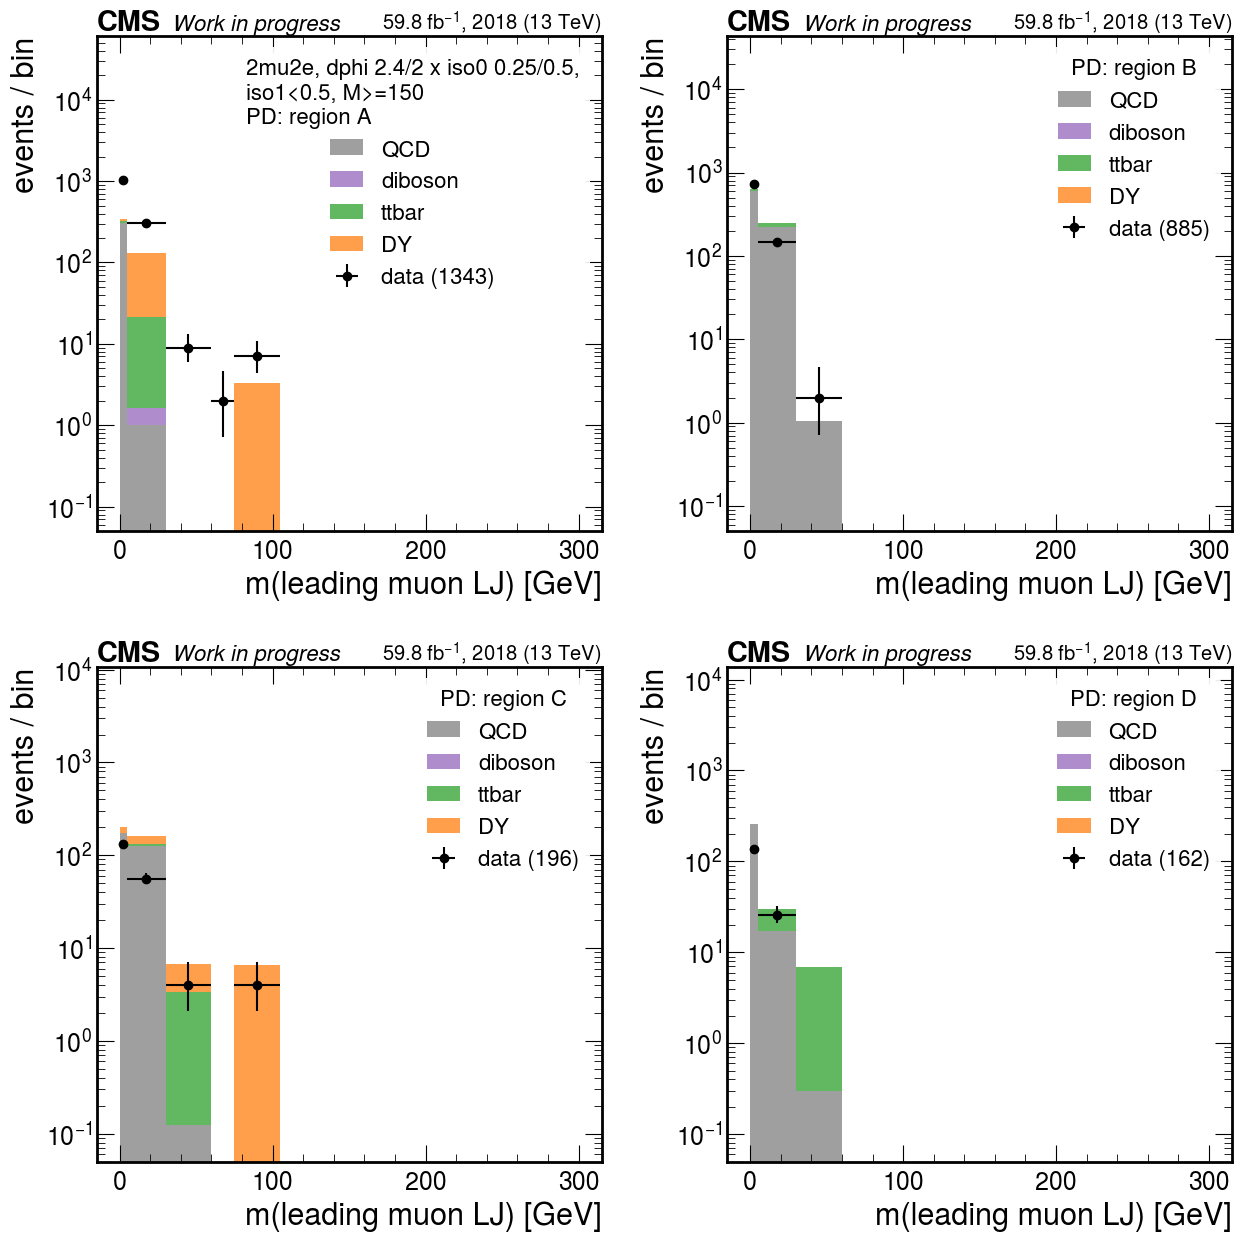

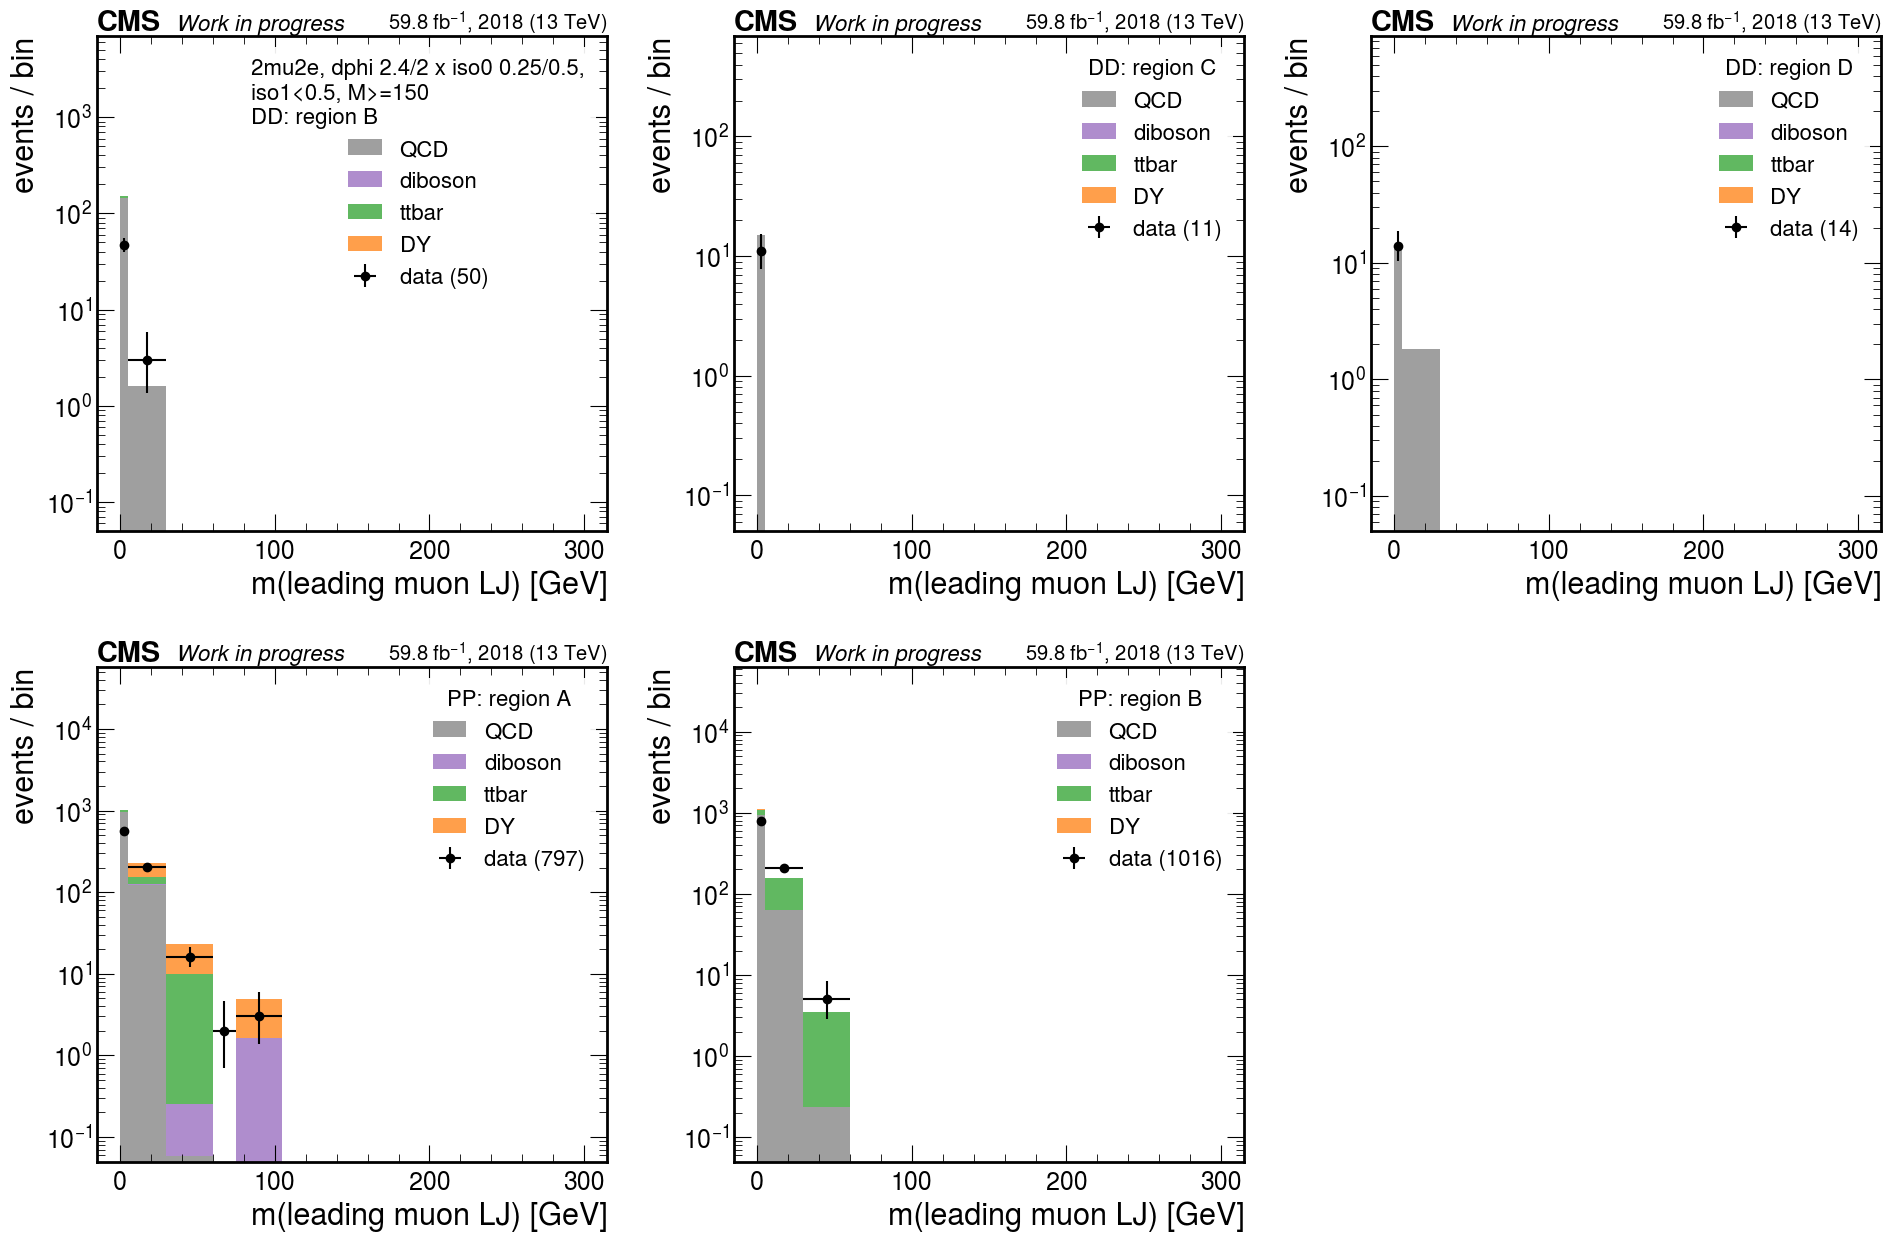

,plane,cut,A,B,C,D,A/B,B/D,C/D,kappa
0,PD,all,1343,885,196,162,1.52 ± 0.07,5.46 -0.47 +0.51,1.21 -0.13 +0.14,1.25 ± 0.15
1,PD,lj0_mass < 75,1336,885,192,162,1.51 ± 0.07,5.46 -0.47 +0.51,1.19 -0.13 +0.14,1.27 ± 0.15
2,PD,lj0_mass >= 75,7,0,4,0,n/a,n/a,n/a,n/a


,plane,cut,A,B,C,D,A/B,B/D,C/D,kappa
0,PP,all,797,1016,121,130,0.78 ± 0.04,7.82 -0.72 +0.80,0.93 -0.12 +0.13,0.84 ± 0.12
1,PP,lj0_mass < 75,794,1016,117,130,0.78 ± 0.04,7.82 -0.72 +0.80,0.90 -0.11 +0.13,0.87 ± 0.12
2,PP,lj0_mass >= 75,3,0,4,0,n/a,n/a,n/a,n/a


,plane,cut,A,B,C,D,A/B,B/D,C/D,kappa
0,DP,all,44,54,5,7,0.81 -0.16 +0.20,7.71 -2.87 +4.91,0.71 -0.38 +0.78,1.14 -0.87 +1.03
1,DP,lj0_mass < 75,44,54,5,7,0.81 -0.16 +0.20,7.71 -2.87 +4.91,0.71 -0.38 +0.78,1.14 -0.87 +1.03
2,DP,lj0_mass >= 75,0,0,0,0,n/a,n/a,n/a,n/a


,plane,cut,A,B,C,D,A/B,B/D,C/D,kappa
0,DD,all,blind,50,11,14,n/a,3.57 -1.04 +1.50,0.79 -0.30 +0.48,n/a
1,DD,lj0_mass < 75,blind,50,11,14,n/a,3.57 -1.04 +1.50,0.79 -0.30 +0.48,n/a
2,DD,lj0_mass >= 75,blind,0,0,0,n/a,n/a,n/a,n/a


data in the Z window (75-105 GeV) per region, and the Drell-Yan simulation there
PD  data: {'A': '7', 'B': '0', 'C': '4', 'D': '0'}  DY: {'A': '3.3', 'B': '0.0', 'C': '6.6', 'D': '0.0'}
PP  data: {'A': '3', 'B': '0', 'C': '4', 'D': '0'}  DY: {'A': '3.3', 'B': '0.0', 'C': '0.0', 'D': '0.0'}
DD  data: {'A': 'blind', 'B': '0', 'C': '0', 'D': '0'}  DY: {'A': '0.0', 'B': '0.0', 'C': '0.0', 'D': '0.0'}


In [3]:
fig = ep.spectrum_figure(d2, g2, "lj0_mass", NOMINAL, [("PD", "PD", r) for r in "ABCD"], "m(leading muon LJ) [GeV]",
                         "estimate_lj0mass_PD_2mu2e", ncols=2)
plt.show()
fig = ep.spectrum_figure(d2, g2, "lj0_mass", NOMINAL, [("DD", "DD", r) for r in "BCD"] + [("PP", "PP", r) for r in "AB"],
                         "m(leading muon LJ) [GeV]", "estimate_lj0mass_DD_PP_2mu2e", ncols=3)
plt.show()
MASS_CUTS = {"all": None, "lj0_mass < 75": ("lj0_mass", None, 75.0), "lj0_mass >= 75": ("lj0_mass", 75.0, None)}
for plane in ("PD", "PP", "DP", "DD"):
    display(el.cut_scan_table(d2, NOMINAL, plane, MASS_CUTS))
print("data in the Z window (75-105 GeV) per region, and the Drell-Yan simulation there")
WINDOW_Z = NOMINAL.with_cut("lj0_mass", 75.0, 105.0)
for plane in ("PD", "PP", "DD"):
    reg_d = ps.regions(d2, WINDOW_Z, plane)
    reg_m = ps.regions(g2["DY"]["2mu2e"], WINDOW_Z, plane)
    print(plane, " data:", {r: tl.fmt_count(reg_d[r]) for r in "ABCD"}, " DY:", {r: f"{reg_m[r][0]:.1f}" for r in "ABCD"})

### 2.2 κ and A/B of PD with the mass cut, against the simulation-subtracted values

`plane_search.ipynb` subtracted the simulated Drell–Yan from PD (κ 1.25 → 1.73 ± 0.37, A/B 1.52 →
1.37 at M ≥ 150 GeV) on a handful of effective simulated events. The cut at 75 GeV does the same
job in the data alone; the two should agree if the simulation's Drell–Yan normalisation is right,
and the cut's value is the one to use either way.

They do not agree, and the previous section says why. The cut leaves the subtraction almost
untouched (131 simulated Drell–Yan events in A against 1336 observed, 62 against 192 in C; 16 and
10 effective events) because the subtracted events were never the Z, so the subtracted κ stays at 1.69 ± 0.35
(1.73 ± 0.37 without the cut) while the data-only value is 1.27 ± 0.15, with A/B = 1.51 ± 0.07.
The subtracted value rests on the simulated low-mass Drell–Yan in a bin where the simulation is
off by a factor of three next door; the data-only value is the one carried forward, and the
subtracted one is an upper variant that measures how much the estimate would move if the
simulation were right. Against the pair mass κ$_{PD}$ is flat — 1.29 ± 0.24, 1.47 ± 0.32,
1.24 ± 0.49, 1.15 −0.62 +0.66 and 0.32 −0.32 +0.41 from 150 GeV to above 600 GeV, χ² 1.0 for
4 degrees of freedom — while κ$_{PP}$ falls with mass (1.43 ± 0.33, 0.86 ± 0.22, 0.28 −0.15 +0.12,
0.41 −0.32 +0.29, 0.26 −0.26 +0.39; χ² 9.5 for 4), so the two planes do not share a trend and
the 0.87 ± 0.12 of PP over all masses is the average of a falling curve.

In [4]:
CUT = NOMINAL.with_cut("lj0_mass", None, 75.0)
WINDOWS = [("M >= 150", NOMINAL),
           ("150-300", dataclasses.replace(NOMINAL, mass=(150.0, 300.0))),
           ("200-300", dataclasses.replace(NOMINAL, mass=(200.0, 300.0))),
           ("M >= 300", dataclasses.replace(NOMINAL, mass=(300.0, None))),
           ("M >= 600", dataclasses.replace(NOMINAL, mass=(600.0, None)))]
WINDOWS_CUT = [(f"{label}, lj0_mass < 75", cfg.with_cut("lj0_mass", None, 75.0)) for label, cfg in WINDOWS]
print("PD without the cut, Drell-Yan subtracted (the plane_search recipe)")
display(ps.subtracted_table(g2, d2, "2mu2e", WINDOWS, plane="PD"))
print("PD with the cut, Drell-Yan subtracted (what is left to subtract)")
display(ps.subtracted_table(g2, d2, "2mu2e", WINDOWS_CUT, plane="PD"))
print("kappa and A/B of the validation planes against the LJ-pair mass, with the cut")
display(ps.mass_table(d2, CUT, planes=("PP", "PD")))

PD without the cut, Drell-Yan subtracted (the plane_search recipe)


,window,data A/B/C/D,DY (simulation) A/B/C/D,DY N_eff A/B/C/D,DY / data,kappa,"kappa, DY subtracted",A/B,"A/B, DY subtracted"
0,M >= 150,1343/885/196/162,134.3/0.0/68.0/0.0,16.5/0.0/11.5/0.0,0.10/0.00/0.35/0.00,1.25 ± 0.15,1.73 ± 0.37,1.52 ± 0.07,1.37 ± 0.07
1,150-300,1068/645/160/129,105.4/0.0/58.2/0.0,12.6/0.0/9.2/0.0,0.10/0.00/0.36/0.00,1.33 ± 0.18,1.89 ± 0.48,1.66 -0.08 +0.09,1.49 ± 0.09
2,200-300,494/324/60/57,31.8/0.0/35.5/0.0,3.6/0.0/5.4/0.0,0.06/0.00/0.59/0.00,1.45 ± 0.31,3.32 ± 2.40,1.52 -0.11 +0.12,1.43 ± 0.12
3,M >= 300,275/240/36/33,28.9/0.0/9.9/0.0,3.9/0.0/3.0/0.0,0.11/0.00/0.27/0.00,1.05 ± 0.30,1.30 -0.52 +0.49,1.15 -0.10 +0.11,1.03 ± 0.11
4,M >= 600,25/17/6/1,3.3/0.0/0.0/0.0,1.0/0.0/0.0/0.0,0.13/0.00/0.00/0.00,0.25 ± 0.26,0.21 -0.21 +0.19,1.47 -0.45 +0.65,1.28 ± 0.47


PD with the cut, Drell-Yan subtracted (what is left to subtract)


,window,data A/B/C/D,DY (simulation) A/B/C/D,DY N_eff A/B/C/D,DY / data,kappa,"kappa, DY subtracted",A/B,"A/B, DY subtracted"
0,"M >= 150, lj0_mass < 75",1336/885/192/162,131.0/0.0/61.5/0.0,15.8/0.0/9.9/0.0,0.10/0.00/0.32/0.00,1.27 ± 0.15,1.69 ± 0.35,1.51 ± 0.07,1.36 ± 0.07
1,"150-300, lj0_mass < 75",1068/645/159/129,105.4/0.0/58.2/0.0,12.6/0.0/9.2/0.0,0.10/0.00/0.37/0.00,1.34 ± 0.18,1.91 ± 0.49,1.66 -0.08 +0.09,1.49 ± 0.09
2,"200-300, lj0_mass < 75",494/324/59/57,31.8/0.0/35.5/0.0,3.6/0.0/5.4/0.0,0.06/0.00/0.60/0.00,1.47 ± 0.32,3.46 ± 2.60,1.52 -0.11 +0.12,1.43 ± 0.12
3,"M >= 300, lj0_mass < 75",268/240/33/33,25.6/0.0/3.3/0.0,3.2/0.0/1.0/0.0,0.10/0.00/0.10/0.00,1.12 ± 0.32,1.12 -0.37 +0.34,1.12 -0.10 +0.11,1.01 ± 0.11
4,"M >= 600, lj0_mass < 75",22/17/4/1,0.0/0.0/0.0/0.0,0.0/0.0/0.0/0.0,0.00/0.00/0.00/0.00,0.32 -0.32 +0.41,0.32 -0.32 +0.41,1.29 -0.40 +0.59,1.29 -0.40 +0.59


kappa and A/B of the validation planes against the LJ-pair mass, with the cut


,plane,bin,A,B,C,D,kappa,A/B
0,PP,150-200,292,316,46,71,1.43 ± 0.33,0.92 -0.07 +0.08
1,PP,200-300,306,381,40,43,0.86 ± 0.22,0.80 -0.06 +0.07
2,PP,300-400,120,194,20,9,0.28 -0.15 +0.12,0.62 -0.07 +0.08
3,PP,400-600,50,92,8,6,0.41 -0.32 +0.29,0.54 -0.09 +0.11
4,PP,>=600,26,33,3,1,0.26 -0.26 +0.39,0.79 -0.20 +0.27
5,PP,all,,,,,0.87 ± 0.12,chi2 of the bins 9.5 / 4
6,PD,150-200,574,321,100,72,1.29 ± 0.24,1.79 -0.12 +0.13
7,PD,200-300,494,324,59,57,1.47 ± 0.32,1.52 -0.11 +0.12
8,PD,300-400,170,144,19,20,1.24 ± 0.49,1.18 -0.13 +0.15
9,PD,400-600,76,79,10,12,1.15 -0.62 +0.66,0.96 -0.15 +0.18


### 2.3 The pixel-0 class by DSA content

The search region's muon LJs with no pixel hit are of two kinds: LJs built from DSA muons only,
and tracker muons that lost their pixel hits. The DSA count separates them. Below, A/B and κ of
every muon class with and without a DSA muon, in the three populations of `plane_search.ipynb`
(egamma LJ prompt at M ≥ 150 GeV; egamma LJ displaced below 150 GeV; egamma LJ displaced at
M ≥ 150 GeV, where the displaced classes are the search region), with the muon-LJ mass cut.

The pixel-0 class is the DSA class: of its 2 events in A of DP, 2 in A of DD below 150 GeV and
13 in B of DD above, all but one carry a DSA muon; the tracker-muon kind without pixel hits is
nearly absent (1 of the 13 in B). The 1–2-hit class is mostly tracker muons everywhere, but its
DSA share is higher in the search plane's B above 150 GeV (17 of 37) than where it is open (10 of
42 in A of DP, 7 of 39 in A of DD below 150 GeV); with the pixel-0 class added, 29 of the 50
events in B of DD carry a DSA muon against 90 of 1336 in A of PD. That matters because the validation plane's ratios depend
on the DSA class: in PD at M ≥ 150 GeV, A/B is 1.67 ± 0.08 without a DSA muon and 0.65 ± 0.10 with
one, κ 1.35 ± 0.18 and 0.68 ± 0.23. The muon-step tests of `plane_search.ipynb` come out as before
with the cut: the A/B of the 1–2-hit class over the prompt class is 1.10 −0.23 +0.29 with the
egamma LJ prompt and 0.94 −0.27 +0.37 with it displaced below 150 GeV (1.06 −0.28 +0.38 on the
iso × iso plane), consistent with one at 25–35% precision; the pixel-0 step, on 2 events in A in
each population, is 0.51 −0.36 +1.03 and 0.11 −0.08 +0.19.

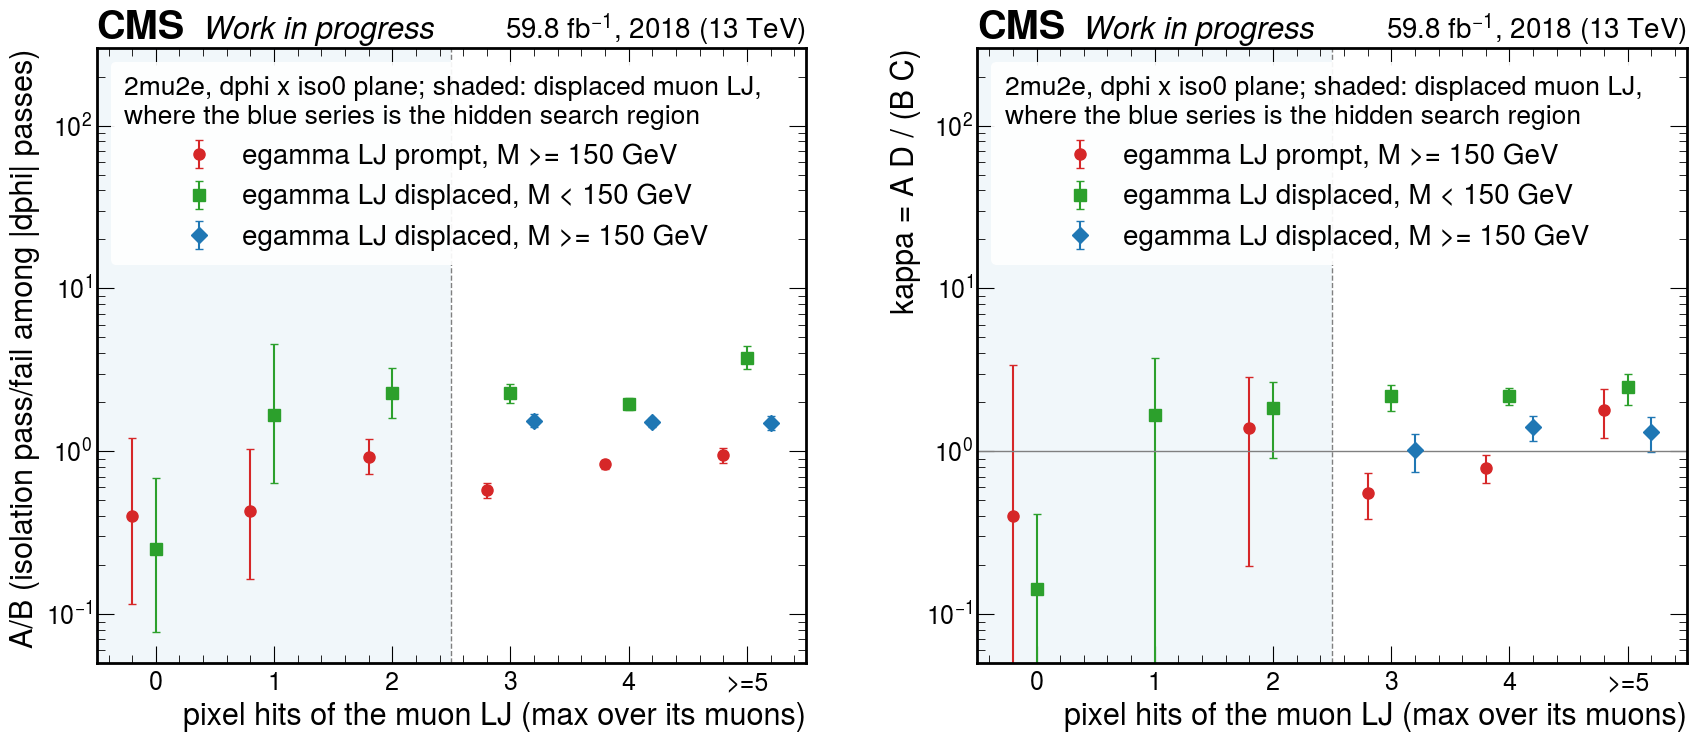

egamma LJ prompt, M >= 150 GeV (DP holds the displaced muon classes, PP the prompt ones)


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,DP,all,44,54,5,7,0.81 -0.16 +0.20,7.71 -2.87 +4.91,0.71 -0.38 +0.78,1.14 -0.87 +1.03,44
1,DP:dsa0,all,32,29,2,4,1.10 -0.28 +0.37,7.25 -3.41 +7.35,0.50 -0.36 +1.10,2.21 -2.21 +4.37,32
2,DP:dsa1+,all,12,25,3,3,0.48 -0.16 +0.24,8.33 -4.35 +10.91,1.00 -0.68 +2.11,0.48 -0.48 +0.73,12
3,DP:dsa2+,all,1,2,0,0,0.50 -0.44 +2.47,n/a,n/a,n/a,1
4,DP:mu0,all,2,5,1,1,0.40 -0.28 +0.80,5.00 -3.80 +29.24,1.00 -0.91 +10.08,0.40 -0.40 +2.99,2
5,DP:mu0:dsa0,all,0,0,0,0,n/a,n/a,n/a,n/a,0
6,DP:mu0:dsa1+,all,2,5,1,1,0.40 -0.28 +0.80,5.00 -3.80 +29.24,1.00 -0.91 +10.08,0.40 -0.40 +2.99,2
7,DP:mu1-2,all,42,49,4,6,0.86 -0.18 +0.22,8.17 -3.23 +5.83,0.67 -0.38 +0.86,1.29 -1.09 +1.36,42
8,DP:mu1-2:dsa0,all,32,29,2,4,1.10 -0.28 +0.37,7.25 -3.41 +7.35,0.50 -0.36 +1.10,2.21 -2.21 +4.37,32
9,DP:mu1-2:dsa1+,all,10,20,2,2,0.50 -0.19 +0.29,10.00 -5.96 +19.85,1.00 -0.77 +3.40,0.50 -0.50 +1.11,10


egamma LJ displaced, M < 150 GeV


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,DD,all,41,26,47,38,1.58 -0.39 +0.51,0.68 -0.17 +0.23,1.24 -0.27 +0.34,1.27 -0.50 +0.47,41
1,DD:dsa0,all,32,15,24,23,2.13 -0.64 +0.94,0.65 -0.21 +0.30,1.04 -0.30 +0.41,2.04 -1.10 +0.98,32
2,DD:dsa1+,all,9,11,23,15,0.82 -0.35 +0.59,0.73 -0.28 +0.44,1.53 -0.49 +0.73,0.53 ± 0.38,9
3,DD:dsa2+,all,2,0,2,0,n/a,n/a,n/a,n/a,2
4,DD:mu0,all,2,8,7,4,0.25 -0.17 +0.43,2.00 -1.07 +2.51,1.75 -0.96 +2.28,0.14 -0.14 +0.27,2
5,DD:mu0:dsa0,all,0,0,0,1,n/a,0.00 -0.00 +5.30,0.00 -0.00 +5.30,n/a,0
6,DD:mu0:dsa1+,all,2,8,7,3,0.25 -0.17 +0.43,2.67 -1.53 +4.13,2.33 -1.37 +3.73,0.11 -0.11 +0.20,2
7,DD:mu1-2,all,39,18,40,34,2.17 -0.60 +0.84,0.53 -0.15 +0.21,1.18 -0.27 +0.35,1.84 -0.83 +0.74,39
8,DD:mu1-2:dsa0,all,32,15,24,22,2.13 -0.64 +0.94,0.68 -0.22 +0.32,1.09 -0.31 +0.44,1.96 -1.06 +0.94,32
9,DD:mu1-2:dsa1+,all,7,3,16,12,2.33 -1.37 +3.73,0.25 -0.15 +0.31,1.33 -0.48 +0.77,1.75 -1.75 +1.63,7


egamma LJ displaced, M >= 150 GeV (DD: A hidden)


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,DD,all,blind,50,11,14,n/a,3.57 -1.04 +1.50,0.79 -0.30 +0.48,n/a,blind
1,DD:dsa0,all,blind,21,7,7,n/a,3.00 -1.21 +2.14,1.00 -0.49 +0.96,n/a,blind
2,DD:dsa1+,all,blind,29,4,7,n/a,4.14 -1.61 +2.82,0.57 -0.32 +0.70,n/a,blind
3,DD:dsa2+,all,blind,8,0,1,n/a,8.00 -5.90 +43.60,0.00 -0.00 +5.30,n/a,blind
4,DD:mu0,all,blind,13,1,3,n/a,4.33 -2.37 +6.12,0.33 -0.29 +1.29,n/a,blind
5,DD:mu0:dsa0,all,blind,1,0,0,n/a,n/a,n/a,n/a,blind
6,DD:mu0:dsa1+,all,blind,12,1,3,n/a,4.00 -2.20 +5.72,0.33 -0.29 +1.29,n/a,blind
7,DD:mu1-2,all,blind,37,10,11,n/a,3.36 -1.10 +1.69,0.91 -0.37 +0.63,n/a,blind
8,DD:mu1-2:dsa0,all,blind,20,7,7,n/a,2.86 -1.16 +2.06,1.00 -0.49 +0.96,n/a,blind
9,DD:mu1-2:dsa1+,all,blind,17,3,4,n/a,4.25 -2.08 +4.59,0.75 -0.49 +1.34,n/a,blind


the muon-step tests of plane_search.ipynb with the mass cut


,test,prompt plane,1-2 pixel hits,ratio 1-2 hits / prompt,ratio 1-2 hits / prompt 3 hits,ratio 1-2 hits / prompt 4 hits,ratio 1-2 hits / prompt 5+ hits,0 pixel hits,ratio 0 hits / prompt
0,"A/B, EGM prompt, M>=150 (analysis plane)",PP: 0.78 ± 0.04 (794/1016),0.86 -0.18 +0.22 (42/49),1.10 -0.23 +0.29,1.49 -0.35 +0.41,1.03 -0.23 +0.28,0.91 -0.22 +0.26,0.40 -0.28 +0.80 (2/5),0.51 -0.36 +1.03
1,"A/B, EGM displaced, M<150 (analysis plane)",PD: 2.30 -0.14 +0.15 (878/382),2.17 -0.60 +0.84 (39/18),0.94 -0.27 +0.37,0.95 -0.30 +0.39,1.11 -0.32 +0.44,0.58 -0.19 +0.24,0.25 -0.17 +0.43 (2/8),0.11 -0.08 +0.19
2,"A/B, EGM displaced, M<150 (iso x iso plane)",PD: 1.94 -0.10 +0.11 (1036/534),2.05 -0.53 +0.72 (43/21),1.06 -0.28 +0.38,1.08 -0.31 +0.40,1.19 -0.32 +0.43,0.73 -0.22 +0.27,0.50 -0.28 +0.58 (4/8),0.26 -0.14 +0.30
3,"kappa, EGM displaced, M<150 (analysis plane)",PD: 2.23 ± 0.19,1.84 -0.83 +0.74,0.83 -0.38 +0.34,0.85 -0.41 +0.37,0.84 -0.39 +0.35,0.74 -0.36 +0.34,,
4,"kappa, EGM displaced, M<150 (iso x iso plane)",PD: 1.46 ± 0.14,1.07 -0.63 +0.52,0.73 -0.44 +0.36,0.60 -0.38 +0.32,0.88 -0.53 +0.44,0.54 -0.34 +0.29,,


In [5]:
fig = pp.pixel_class_figure(d2, CUT)
plt.show()
LOW = dataclasses.replace(CUT, mass=(None, 150.0))
DSA_SPLITS = (None, "dsa0", "dsa1+", "dsa2+", "mu0", "mu0:dsa0", "mu0:dsa1+", "mu1-2", "mu1-2:dsa0", "mu1-2:dsa1+", "mu3+")
print("egamma LJ prompt, M >= 150 GeV (DP holds the displaced muon classes, PP the prompt ones)")
display(el.class_grid_table(d2, CUT, ("DP", "PP"), DSA_SPLITS))
print("egamma LJ displaced, M < 150 GeV")
display(el.class_grid_table(d2, LOW, ("DD", "PD"), DSA_SPLITS))
print("egamma LJ displaced, M >= 150 GeV (DD: A hidden)")
display(el.class_grid_table(d2, CUT, ("DD", "PD"), DSA_SPLITS))
print("the muon-step tests of plane_search.ipynb with the mass cut")
display(ps.muon_step_tests(d2, CUT))

### 2.4 The 2μ2e estimate from the search channel alone

The recipe of `plane_search.ipynb` with the mass cut: for the 1–2-pixel-hit class the in-plane
B C/D, the same times κ$_{PD}$, and B × (A/B)$_{PD}$; for the pixel-0 class B × (A/B)$_{PD}$ times
the pixel-0/prompt step ratio measured in each open pixel-0 population. The last table evaluates
B × (A/B)$_{PD}$ per DSA class of the muon LJ and sums the two, since the previous section found
the search plane's B DSA-rich and PD's A/B a factor 2.6 apart between the classes; its last row,
below 150 GeV where A of the DD plane is open, is the one direct closure test of this form.

Above 150 GeV the 1–2-hit class has B/C/D = 37/10/11: in-plane 33.6 ± 15.7, times κ$_{PD}$
42.8 ± 20.7, and B × (A/B)$_{PD}$ = 55.9 ± 9.5. The windows that matter for the signal (section 6:
the 500 and 800 GeV points sit above 300 GeV) have no usable in-plane estimate: at
M ≥ 300 GeV the plane holds B/C/D = 16/5/1, so B C/D = 80 ± 90 on one event in D, against
17.9 ± 4.8 from B × (A/B)$_{PD}$ (A/B 1.12 ± 0.10 in that window); above 600 GeV B/C/D = 3/0/0.
Split by DSA class the recipe comes out lower than the inclusive one over all pixel classes —
53.9 ± 9.1 against 75.5 ± 11.2 above 150 GeV (B = 50, of which 29 carry a DSA muon; the 1–2-hit
class alone gives 55.9 ± 9.5), and 15.8 ± 4.5 against 17.9 ± 4.8 above 300 GeV, where 5 of the
16 do — and the sum over the classes is the form to prefer; the muon-step tests of the previous
section, which check the pixel-hit step rather than the DSA split, are the nearest justification
at 25–35%. Below 150 GeV, where A is open with 41 events, the class-summed form predicts
52.8 ± 11.5 and the inclusive one 59.8 ± 12.4, ratios of 1.29 ± 0.35 and 1.46 ± 0.38 to the
observation: the one direct test of the recipe, an over-prediction of the size of the +27% of
κ$_{PD}$ above 150 GeV at a precision that does not separate it from closure, in a window where
PD itself fails (κ 2.23 ± 0.19, section 6). The transfer runs along the isolation axis, B × (A/B),
because that is the ratio the muon-step tests check and because B is the populated sideband
(50/11/14 events in B/C/D above 150 GeV, 16/5/1 above 300); the same transfer along the
$|\Delta\phi|$ axis, C × (A/C)$_{PD}$, is listed beside it for comparison and agrees within its
two-to-four-times larger errors — 76.5 ± 23.9 against 75.5 ± 11.2 above 150 GeV, 40.6 ± 20.3
against 17.9 ± 4.8 above 300 GeV, and below 150 GeV 64.8 ± 10.1 against 41 observed, the same
over-prediction. The pixel-0 class contributes 13 events to B above
150 GeV and none at M ≥ 300 GeV; its estimate rests on a step ratio measured on 2 events and is
2 to 10 events above 150 GeV (10.0 −7.7 +20.3 and 2.1 −1.6 +3.7 from the two populations the step
is taken from) and nothing above 300 GeV. Without the cut the estimates move by less than half an
event.

In [6]:
display(ps.estimate_table(d2, WINDOWS_CUT))
print("the same without the mass cut, for reference")
display(ps.estimate_table(d2, WINDOWS))
print("B x A/B of PD per DSA class of the muon LJ, all pixel classes, and summed, with C x A/C beside it; the last row has A open")
LOW2_CUT = dataclasses.replace(CUT, mass=(None, 150.0))
display(el.class_recipe_table(d2, WINDOWS_CUT + [("M < 150, lj0_mass < 75", LOW2_CUT)]))

,window,DD 1-2 hits B/C/D,in-plane B C/D,kappa PD,x kappa PD,A/B PD,B x A/B PD,DD 0 hits B,0 hits: B x A/B PD x step (egamma prompt),"0 hits: B x A/B PD x step (egamma displaced, M<150)"
0,"M >= 150, lj0_mass < 75",37/10/11,33.6 ± 15.7,1.27 ± 0.15,42.8 ± 20.7,1.51 ± 0.07,55.9 ± 9.5,13,10.0 -7.7 +20.3 (step 0.51 -0.36 +1.03),2.1 -1.6 +3.7 (step 0.11 -0.08 +0.19)
1,"150-300, lj0_mass < 75",21/5/10,10.5 ± 6.2,1.34 ± 0.18,14.1 ± 8.5,1.66 -0.08 +0.09,34.8 ± 7.8,13,11.0 -8.4 +22.3 (step 0.51 -0.36 +1.03),2.3 -1.8 +4.1 (step 0.11 -0.08 +0.19)
2,"200-300, lj0_mass < 75",14/1/6,2.3 ± 2.6,1.47 ± 0.32,3.4 ± 3.9,1.52 -0.11 +0.12,21.3 ± 5.9,6,4.7 -3.9 +9.6 (step 0.51 -0.36 +1.03),1.0 -0.8 +1.8 (step 0.11 -0.08 +0.19)
3,"M >= 300, lj0_mass < 75",16/5/1,80.0 ± 89.9,1.12 ± 0.32,89.3 ± 103.7,1.12 -0.10 +0.11,17.9 ± 4.8,0,0.0 -0.0 +1.1 (step 0.51 -0.36 +1.03),0.0 -0.0 +0.2 (step 0.11 -0.08 +0.19)
4,"M >= 600, lj0_mass < 75",3/0/0,n/a,0.32 -0.32 +0.41,n/a,1.29 -0.40 +0.59,3.9 -2.5 +2.9,0,0.0 -0.0 +1.2 (step 0.51 -0.36 +1.03),0.0 -0.0 +0.3 (step 0.11 -0.08 +0.19)


the same without the mass cut, for reference


,window,DD 1-2 hits B/C/D,in-plane B C/D,kappa PD,x kappa PD,A/B PD,B x A/B PD,DD 0 hits B,0 hits: B x A/B PD x step (egamma prompt),"0 hits: B x A/B PD x step (egamma displaced, M<150)"
0,M >= 150,37/10/11,33.6 ± 15.7,1.25 ± 0.15,42.2 ± 20.3,1.52 ± 0.07,56.1 ± 9.6,13,10.1 -7.7 +20.3 (step 0.51 -0.36 +1.02),2.1 -1.6 +3.8 (step 0.11 -0.08 +0.19)
1,150-300,21/5/10,10.5 ± 6.2,1.33 ± 0.18,14.0 ± 8.5,1.66 -0.08 +0.09,34.8 ± 7.8,13,11.0 -8.4 +22.2 (step 0.51 -0.36 +1.02),2.3 -1.8 +4.1 (step 0.11 -0.08 +0.19)
2,200-300,14/1/6,2.3 ± 2.6,1.45 ± 0.31,3.4 ± 3.8,1.52 -0.11 +0.12,21.3 ± 5.9,6,4.7 -3.8 +9.5 (step 0.51 -0.36 +1.02),1.0 -0.8 +1.8 (step 0.11 -0.08 +0.19)
3,M >= 300,16/5/1,80.0 ± 89.9,1.05 ± 0.30,84.0 ± 97.4,1.15 -0.10 +0.11,18.3 ± 4.9,0,0.0 -0.0 +1.1 (step 0.51 -0.36 +1.02),0.0 -0.0 +0.2 (step 0.11 -0.08 +0.19)
4,M >= 600,3/0/0,n/a,0.25 ± 0.26,n/a,1.47 -0.45 +0.65,4.4 -2.9 +3.2,0,0.0 -0.0 +1.4 (step 0.51 -0.36 +1.02),0.0 -0.0 +0.3 (step 0.11 -0.08 +0.19)


B x A/B of PD per DSA class of the muon LJ, all pixel classes, and summed, with C x A/C beside it; the last row has A open


,window,DD B dsa0,A/B PD dsa0,B x A/B dsa0,DD B dsa1+,A/B PD dsa1+,B x A/B dsa1+,sum over classes,inclusive B x A/B,inclusive C x A/C,DD A observed
0,"M >= 150, lj0_mass < 75",21,1.67 ± 0.08,35.0 ± 7.8,29,0.65 -0.09 +0.10,18.9 -4.3 +4.6,53.9 ± 9.1,75.5 ± 11.2,76.5 ± 23.9,blind
1,"150-300, lj0_mass < 75",10,1.83 -0.10 +0.10,18.3 ± 5.9,24,0.72 -0.11 +0.13,17.2 -4.4 +4.7,35.6 ± 7.5,56.3 ± 10.1,40.3 ± 16.9,blind
2,"200-300, lj0_mass < 75",6,1.65 -0.13 +0.14,9.9 ± 4.1,14,0.81 -0.17 +0.22,11.4 -3.9 +4.3,21.3 -5.7 +6.0,30.5 ± 7.2,8.4 ± 8.5,blind
3,"M >= 300, lj0_mass < 75",11,1.23 -0.12 +0.13,13.5 ± 4.3,5,0.46 -0.13 +0.19,2.3 -1.2 +1.4,15.8 ± 4.5,17.9 ± 4.8,40.6 ± 20.3,blind
4,"M >= 600, lj0_mass < 75",3,1.83 -0.63 +0.97,5.5 -3.7 +4.3,0,0.00 -0.00 +0.45,0.0 ± 0.0,5.5 -3.7 +4.3,3.9 -2.5 +2.9,0.0 -0.0 +10.1,blind
5,"M < 150, lj0_mass < 75",15,2.42 -0.16 +0.17,36.3 ± 9.7,11,1.50 -0.27 +0.33,16.5 -5.8 +6.2,52.8 ± 11.5,59.8 ± 12.4,64.8 ± 10.1,41


## 3. 2μ2e: the proxy-muon region

### 3.1 What is in it

The region's composition from the simulation, with and without a b-jet, and its data counts per
plane: the proxy region has the search channel's four planes, all open. Weinan's validation region
is the b-tagged part; the b-vetoed part is the larger sample and, in 2μ2e, holds negligible signal
(at most 0.42 events in any of its A regions, against 383 observed in DD).

The region is large — 4625/776/1341/161 events in the four regions of PP, 6413/444/2029/130 in
PD, 419/55/123/25 in DD, 342/92/101/23 in DP, all open — and it is not the search channel's
population. The lone muon is isolated far more often than a muon LJ: A/B, the isolation
pass/fail ratio among back-to-back events, is 6.0 in PP and 14.4 in PD against 0.78 and 1.51 in
the search channel, and C/D is 8.3 and 15.6 against 0.9 and 1.2. The simulation (whose
normalisation in these planes is not to be trusted, section 2.1) fills A of PP with Drell–Yan and
tt̄ in equal parts and A of PD with Drell–Yan (3790 of 4250 simulated events), with tt̄ ahead of
QCD in B of PP (383 against 156); the b-tag selects the tt̄ part (1218 of 1261 simulated events in
A of PP) and leaves 1652 events there, 523 in A of PD and 36 in A of DD. The signal in the A
regions of DD, PD and DP is at most 0.44 events at the stored cross sections (the 800 GeV point in
DD, against 419 observed), so every corner can be read.

In [7]:
pg = {t: tl.group_cubes(PROXY, "bkg", prefix="abcd8d_proxy", topologies=(t,)) for t in tl.TOPOLOGIES}
pg2 = pg["2mu2e"]
print("process groups, proxy:", {t: sorted(g) for t, g in pg.items()})
for b in ("all", ">=1 b-jet", "no b-jet"):
    print(f"--- {b}")
    display(ps.mc_composition_table(pg2, p2, "2mu2e", el.with_btag(NOMINAL, b)))
print("signal in region A of the proxy planes at the stored cross sections (data count in brackets)")
SIGNAL_POINTS = {"2mu2e": ["2Mu2E_200GeV_0p25GeV_1p0mm", "2Mu2E_500GeV_0p25GeV_0p4mm", "2Mu2E_800GeV_0p25GeV_0p25mm",
                           "2Mu2E_1000GeV_0p25GeV_0p2mm", "2Mu2E_800GeV_1p2GeV_1p2mm", "2Mu2E_1000GeV_1p2GeV_0p96mm",
                           "2Mu2E_800GeV_0p25GeV_1p2mm"],
                 "4mu": ["4Mu_200GeV_0p25GeV_1p0mm", "4Mu_500GeV_0p25GeV_0p4mm", "4Mu_800GeV_0p25GeV_0p25mm",
                         "4Mu_1000GeV_0p25GeV_0p2mm", "4Mu_800GeV_1p2GeV_1p2mm", "4Mu_1000GeV_1p2GeV_0p96mm",
                         "4Mu_800GeV_0p25GeV_1p2mm"]}
display(el.signal_a_table(PROXY, SIGNAL_POINTS["2mu2e"], "2mu2e", [("M >= 150", NOMINAL)], ("DD", "PD", "DP"),
                          prefix="abcd8d_proxy", btag=("all", ">=1 b-jet"), data=p2))

process groups, proxy: {'2mu2e': ['DY', 'QCD', 'diboson', 'ttbar'], '4mu': ['DY', 'QCD', 'diboson', 'ttbar']}
--- all


,plane,region,data,simulation,N_eff,DY,QCD,diboson,ttbar,kappa (simulation)
0,PP,A,4625,3540.8 ± 103.2,1176.5,1538.0,0.8,371.7,1630.3,1.03 ± 0.24
1,PP,B,776,548.1 ± 46.4,139.3,6.5,156.2,2.5,383.0,
2,PP,C,1341,735.8 ± 46.6,249.8,344.9,0.8,75.9,314.3,
3,PP,D,161,117.7 ± 23.7,24.6,6.5,61.6,0.4,49.1,
4,DP,A,342,228.2 ± 27.3,69.9,97.4,0.1,19.5,111.3,0.07 ± 0.04
5,DP,B,92,54.4 ± 13.7,15.9,0.0,14.8,0.4,39.3,
6,DP,C,101,43.0 ± 11.3,14.4,22.8,0.0,3.9,16.4,
7,DP,D,23,0.7 ± 0.2,9.6,0.0,0.7,0.0,0.0,
8,PD,A,6413,4252.5 ± 117.5,1309.9,3789.8,9.4,80.1,373.2,0.44 ± 0.14
9,PD,B,444,448.3 ± 107.5,17.4,22.8,375.8,0.6,49.1,


--- >=1 b-jet


,plane,region,data,simulation,N_eff,DY,QCD,diboson,ttbar,kappa (simulation)
0,PP,A,1652,1261.0 ± 64.1,386.4,39.0,0.1,4.0,1217.8,1.10 ± 0.35
1,PP,B,379,269.2 ± 31.7,71.9,0.0,62.8,0.2,206.2,
2,PP,C,497,281.3 ± 30.2,86.9,26.0,0.8,2.4,252.1,
3,PP,D,78,66.2 ± 17.8,13.9,0.0,36.7,0.0,29.5,
4,DP,A,136,89.0 ± 17.0,27.4,6.5,0.0,0.6,81.8,0.05 ± 0.03
5,DP,B,44,39.1 ± 11.9,10.7,0.0,12.7,0.2,26.2,
6,DP,C,37,20.2 ± 8.0,6.4,3.3,0.0,0.6,16.4,
7,DP,D,18,0.4 ± 0.2,5.5,0.0,0.4,0.0,0.0,
8,PD,A,523,268.8 ± 29.5,83.2,19.5,1.0,2.8,245.5,0.41 ± 0.17
9,PD,B,190,111.0 ± 25.0,19.7,0.0,104.5,0.0,6.5,


--- no b-jet


,plane,region,data,simulation,N_eff,DY,QCD,diboson,ttbar,kappa (simulation)
0,PP,A,2973,2279.9 ± 80.9,794.5,1499.0,0.7,367.7,412.5,0.93 ± 0.31
1,PP,B,397,278.9 ± 33.9,67.7,6.5,93.4,2.3,176.8,
2,PP,C,844,454.5 ± 35.4,164.4,318.9,0.0,73.4,62.2,
3,PP,D,83,51.5 ± 15.7,10.7,6.5,24.9,0.4,19.6,
4,DP,A,206,139.2 ± 21.3,42.6,90.9,0.0,18.9,29.5,0.11 ± 0.08
5,DP,B,48,15.3 ± 6.6,5.4,0.0,2.0,0.2,13.1,
6,DP,C,64,22.8 ± 8.0,8.1,19.5,0.0,3.3,0.0,
7,DP,D,5,0.3 ± 0.1,4.2,0.0,0.3,0.0,0.0,
8,PD,A,5890,3983.6 ± 113.7,1226.7,3770.3,8.4,77.3,127.7,0.37 ± 0.16
9,PD,B,254,337.2 ± 104.5,10.4,22.8,271.3,0.6,42.6,


signal in region A of the proxy planes at the stored cross sections (data count in brackets)


,point,window,DD A,"DD A, >=1 b-jet",PD A,"PD A, >=1 b-jet",DP A,"DP A, >=1 b-jet"
0,2Mu2E_200GeV_0p25GeV_1p0mm,M >= 150,0.00 (419),0.00 (36),0.00 (6413),0.00 (523),0.00 (342),0.00 (136)
1,2Mu2E_500GeV_0p25GeV_0p4mm,M >= 150,0.05 (419),0.00 (36),0.00 (6413),0.00 (523),0.01 (342),0.00 (136)
2,2Mu2E_800GeV_0p25GeV_0p25mm,M >= 150,0.44 (419),0.02 (36),0.03 (6413),0.00 (523),0.06 (342),0.00 (136)
3,2Mu2E_1000GeV_0p25GeV_0p2mm,M >= 150,0.02 (419),0.00 (36),0.00 (6413),0.00 (523),0.00 (342),0.00 (136)
4,2Mu2E_800GeV_1p2GeV_1p2mm,M >= 150,0.33 (419),0.01 (36),0.01 (6413),0.00 (523),0.04 (342),0.00 (136)
5,2Mu2E_1000GeV_1p2GeV_0p96mm,M >= 150,0.01 (419),0.00 (36),0.00 (6413),0.00 (523),0.00 (342),0.00 (136)
6,2Mu2E_800GeV_0p25GeV_1p2mm,M >= 150,0.21 (419),0.01 (36),0.00 (6413),0.00 (523),0.01 (342),0.00 (136)


### 3.2 Closure of the proxy planes, by class and b-tag

κ, B/D, C/D and A/B of every proxy plane, split by the lone muon's class (pixel hits ≥ 3, 1–2, 0,
DSA) and the egamma LJ's class (electron with lost hits, photon-only), for the whole region, its
b-tagged part and its b-vetoed part; then the same ratios next to the search plane's open ratios
with their pulls. The proxy DD plane is the analogue of the search plane with A open: its κ is the
closure test the search channel cannot run on itself, and the question is whether its open ratios
B/D and C/D agree with the search plane's.

They do not, except in the b-tagged part. The proxy DD plane has B/D = 2.2 −0.5 +0.7 and
C/D = 4.9 −1.0 +1.4 against the search plane's 3.6 −1.0 +1.5 and 0.8 −0.3 +0.5 (pulls −1.1 and
+3.4); its b-tagged part has 2.7 −1.0 +1.6 and 1.8 −0.7 +1.2 (pulls −0.5 and +1.2) — the search
plane's ratios, on 36 events in A — and its b-vetoed part has C/D = 6.7 −1.7 +2.4 (pull +3.8).
The b-tag requirement of the thesis brings the open ratios within errors of the search plane's,
though the lone muon's A/B stays 5.6 times the muon LJ's in PP and 1.8 times in PD (section 3.3):
a muon from a heavy-flavour jet fails the isolation more often than an isolated lone muon, not as
often as a muon LJ. Closure, nominal configuration:
PP 0.72 ± 0.07, DP 0.85 −0.27 +0.22, PD 0.93 ± 0.10, DD 1.55 −0.51 +0.40 for the whole region;
0.68 ± 0.10, 1.50 −0.63 +0.53, 0.61 ± 0.12 and 0.84 −0.56 +0.47 with a b-jet; 0.74 ± 0.10,
0.34 −0.28 +0.15, 1.02 −0.15 +0.13 and 1.85 −0.82 +0.59 without. The two planes measured at 10%
precision disagree with each other (PP −28%, PD −7%) and with their search-channel counterparts
(PP −13%, PD +27%, section 6), and the DD planes are measured at 30–70%. By class, every lone-muon
and egamma-LJ class of the whole proxy DD plane has κ between 1.3 and 2.4 with 40–100% uncertainty
(the figure; the b-tagged classes span 0.44–3.0); against the pair mass κ of PP goes from
0.64 ± 0.09 at 150–200 GeV to 1.6 −1.0 +0.7 at 400–600 GeV and κ of PD from 0.79 −0.14 +0.12 to
1.5 −1.1 +0.7, both consistent with flat (χ² 2.5 and 2.1 for 4) where the search channel's PP
falls.

,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,4625,776,1341,161,5.96 ± 0.24,4.82 -0.42 +0.46,8.33 -0.69 +0.76,0.72 -0.07 +0.07,4625
1,PP,>=1 b-jet,1652,379,497,78,4.36 -0.25 +0.26,4.86 -0.60 +0.69,6.37 -0.77 +0.88,0.68 -0.10 +0.09,1652
2,PP,no b-jet,2973,397,844,83,7.49 -0.40 +0.42,4.78 -0.57 +0.65,10.17 -1.16 +1.32,0.74 -0.10 +0.09,2973
3,PP:mu3+,all,4625,776,1341,161,5.96 ± 0.24,4.82 -0.42 +0.46,8.33 -0.69 +0.76,0.72 -0.07 +0.07,4625
4,PP:mu3+,>=1 b-jet,1652,379,497,78,4.36 -0.25 +0.26,4.86 -0.60 +0.69,6.37 -0.77 +0.88,0.68 -0.10 +0.09,1652
5,PP:mu3+,no b-jet,2973,397,844,83,7.49 -0.40 +0.42,4.78 -0.57 +0.65,10.17 -1.16 +1.32,0.74 -0.10 +0.09,2973
6,PP:dsa0,all,4625,776,1341,161,5.96 ± 0.24,4.82 -0.42 +0.46,8.33 -0.69 +0.76,0.72 -0.07 +0.07,4625
7,PP:dsa0,>=1 b-jet,1652,379,497,78,4.36 -0.25 +0.26,4.86 -0.60 +0.69,6.37 -0.77 +0.88,0.68 -0.10 +0.09,1652
8,PP:dsa0,no b-jet,2973,397,844,83,7.49 -0.40 +0.42,4.78 -0.57 +0.65,10.17 -1.16 +1.32,0.74 -0.10 +0.09,2973
9,PP:dsa1+,all,0,0,0,0,n/a,n/a,n/a,n/a,0


against the search plane's open ratios


,plane,b-tag,A,B,C,D,kappa,B/D,B/D pull vs DD,C/D,C/D pull vs DD,A/B
0,PP,all,4625,776,1341,161,0.72 -0.07 +0.07,4.82 -0.42 +0.46,+0.8,8.33 -0.69 +0.76,+4.8,5.96 ± 0.24
1,PP,>=1 b-jet,1652,379,497,78,0.68 -0.10 +0.09,4.86 -0.60 +0.69,+0.8,6.37 -0.77 +0.88,+4.2,4.36 -0.25 +0.26
2,PP,no b-jet,2973,397,844,83,0.74 -0.10 +0.09,4.78 -0.57 +0.65,+0.8,10.17 -1.16 +1.32,+5.2,7.49 -0.40 +0.42
3,DP,all,342,92,101,23,0.85 -0.27 +0.22,4.00 -0.91 +1.20,+0.3,4.39 -0.99 +1.30,+3.2,3.72 -0.43 +0.49
4,DP,>=1 b-jet,136,44,37,18,1.50 -0.63 +0.53,2.44 -0.66 +0.92,-0.8,2.06 -0.57 +0.80,+1.7,3.09 -0.53 +0.64
5,DP,no b-jet,206,48,64,5,0.34 -0.28 +0.15,9.60 -4.07 +7.85,+1.5,12.80 -5.36 +10.29,+3.8,4.29 -0.68 +0.81
6,PD,all,6413,444,2029,130,0.93 -0.10 +0.09,3.42 -0.34 +0.38,-0.1,15.61 -1.41 +1.55,+6.1,14.44 -0.71 +0.75
7,PD,>=1 b-jet,523,190,229,51,0.61 -0.12 +0.11,3.73 -0.58 +0.69,+0.1,4.49 -0.69 +0.82,+3.4,2.75 -0.23 +0.25
8,PD,no b-jet,5890,254,1800,79,1.02 -0.15 +0.13,3.22 -0.41 +0.47,-0.3,22.78 -2.60 +2.95,+6.8,23.19 -1.48 +1.59
9,DD,all,419,55,123,25,1.55 -0.51 +0.40,2.20 -0.52 +0.68,-1.1,4.92 -1.05 +1.36,+3.4,7.62 -1.08 +1.27


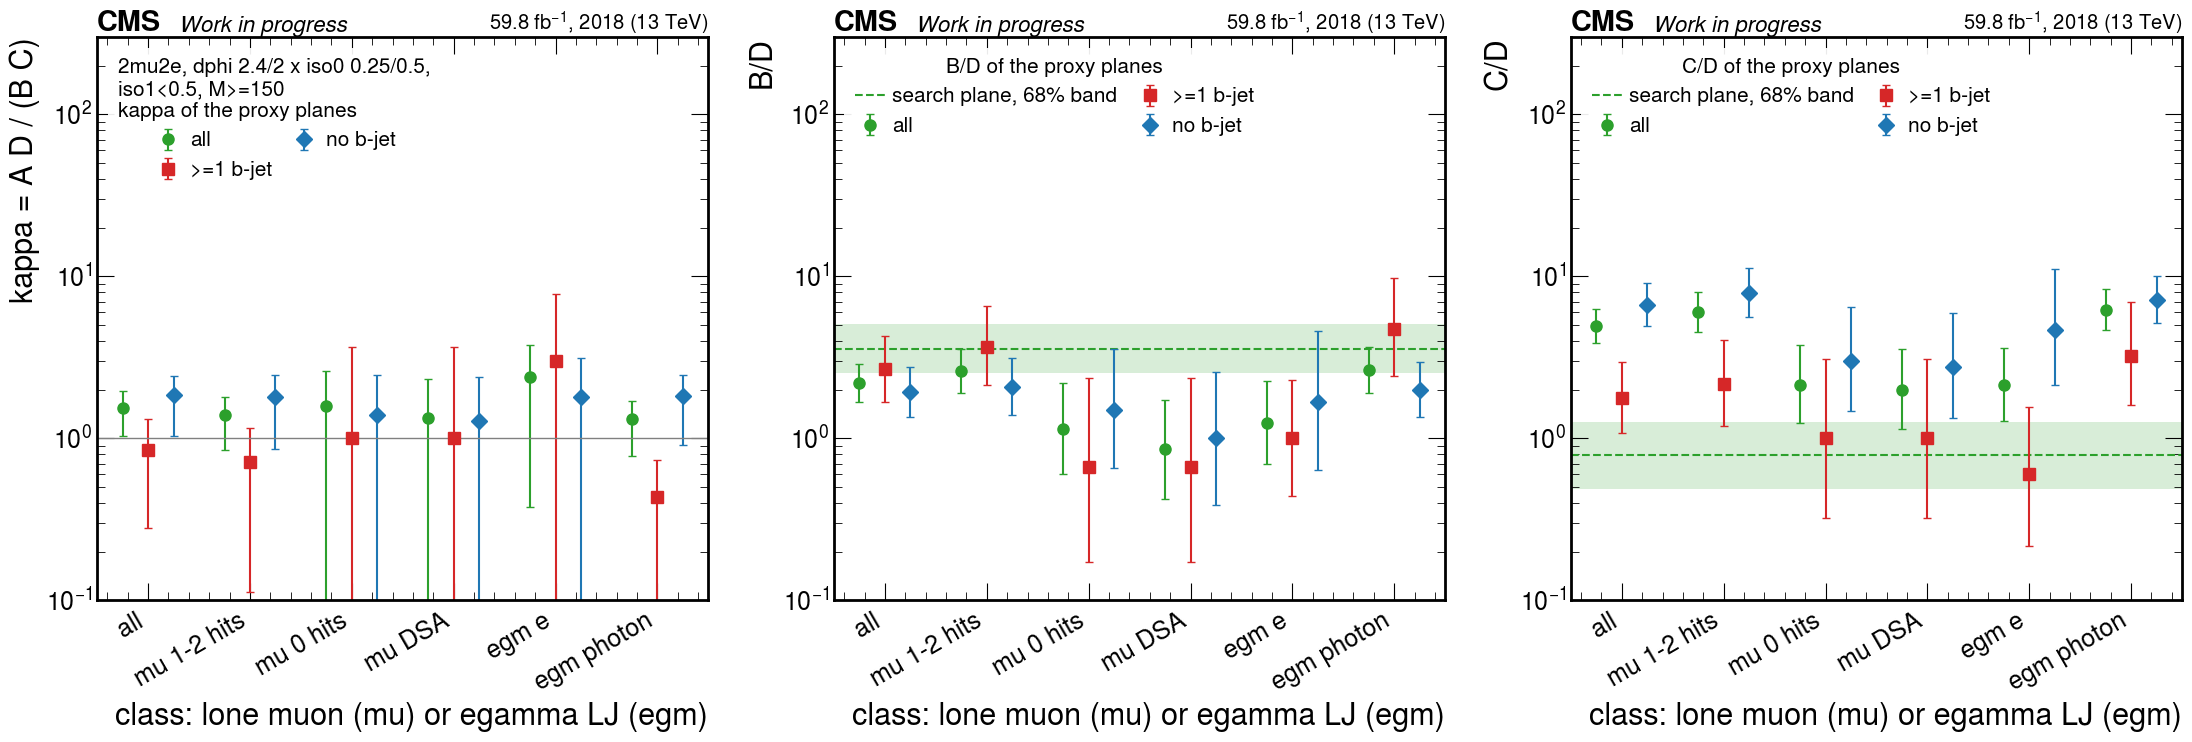

the proxy planes against the LJ-pair mass (whole region)


,plane,bin,A,B,C,D,kappa,A/B
0,PP,150-200,1953,381,679,85,0.64 -0.09 +0.08,5.13 -0.29 +0.30
1,PP,200-300,1731,289,465,52,0.67 -0.12 +0.11,5.99 -0.38 +0.41
2,PP,300-400,554,77,116,15,0.93 -0.37 +0.27,7.19 -0.87 +0.99
3,PP,400-600,298,24,63,8,1.58 -1.04 +0.65,12.42 -2.57 +3.31
4,PP,>=600,89,5,18,1,0.99 -0.99 +0.82,17.80 -7.38 +14.09
5,PP,all,,,,,0.72 -0.07 +0.07,chi2 of the bins 2.5 / 4
6,PD,150-200,3183,228,1065,60,0.79 -0.14 +0.12,13.96 -0.95 +1.03
7,PD,200-300,2202,153,704,48,0.98 -0.20 +0.17,14.39 -1.20 +1.31
8,PD,300-400,643,41,172,14,1.28 -0.56 +0.40,15.68 -2.49 +2.99
9,PD,400-600,299,19,72,7,1.53 -1.13 +0.67,15.74 -3.61 +4.81


In [8]:
PLANES = ("PP", "DP", "PD", "DD")
PROXY_SPLITS = (None, "mu3+", "mu1-2", "mu0", "dsa0", "dsa1+", "e", "g")
BTAGS = ("all", ">=1 b-jet", "no b-jet")
display(el.class_grid_table(p2, NOMINAL, PLANES, PROXY_SPLITS, btag=BTAGS))
print("against the search plane's open ratios")
display(el.cross_compatibility_table(p2, PLANES + ("DD:dsa1+", "DD:mu0", "DD:mu1-2", "DD:g", "DD:e"), d2, NOMINAL, btag=BTAGS))
dd = ps.regions(d2, NOMINAL, "DD")
REF = {"B/D": tl.ratio(dd["B"], dd["D"]), "C/D": tl.ratio(dd["C"], dd["D"])}
CLASSES = [("all", None), ("mu 1-2 hits", "mu1-2"), ("mu 0 hits", "mu0"), ("mu DSA", "dsa1+"), ("egm e", "e"), ("egm photon", "g")]
fig = ep.class_ratio_figure(p2, NOMINAL, [("all", "DD", "tab:green", "o", "all"), (">=1 b-jet", "DD", "tab:red", "s", ">=1 b-jet"),
                                          ("no b-jet", "DD", "tab:blue", "D", "no b-jet")],
                            CLASSES, reference=REF, name="estimate_proxy_classes_2mu2e", xlabel="class: lone muon (mu) or egamma LJ (egm)")
plt.show()
print("the proxy planes against the LJ-pair mass (whole region)")
display(ps.mass_table(p2, NOMINAL, planes=("PP", "PD", "DD")))

### 3.3 With the egamma LJ's isolation as the second axis

The search plane's A/B ratio is the isolation pass/fail ratio of the muon LJ among back-to-back
events; the proxy region measures the same ratio for a lone muon. Whether that ratio transfers from
a lone muon to a two-muon LJ is the assumption of the method, and the one test of it available in
the data is the comparison of the prompt classes: PP of the proxy region against PP of the search
channel (both open), and the same for PD.

The ratio does not transfer: A/B of the lone muon is 7.6 ± 0.5 times the muon LJ's in PP and
9.5 ± 0.6 times in PD (5.6 ± 0.4 and 1.8 ± 0.2 with a b-jet, 9.6 ± 0.7 and 15.3 ± 1.2 without).
A lone muon and a two-muon LJ are different objects as far as isolation goes, and the b-tagged
PD plane, where the factor is smallest, is still a factor 1.8 away. So the proxy region cannot
supply the search plane's factors; what it can supply is a κ, if its planes behaved like the
search channel's, which the previous section shows they do not.

In [9]:
rows = []
for plane in ("PP", "PD", "DP", "DD"):
    for b in BTAGS:
        rp = ps.regions(p2, el.with_btag(NOMINAL, b), plane)
        rs = ps.regions(d2, NOMINAL, plane)
        rows.append({"plane": plane, "proxy b-tag": b,
                     "proxy A/B/C/D": "/".join(tl.fmt_count(rp[r]) for r in "ABCD"), "search A/B/C/D": "/".join(tl.fmt_count(rs[r]) for r in "ABCD"),
                     "A/B proxy": tl.fmt(tl.ratio(rp["A"], rp["B"]), 2), "A/B search": tl.fmt(tl.ratio(rs["A"], rs["B"]), 2),
                     "ratio": tl.fmt(tl.ratio_of_ratios(tl.ratio(rp["A"], rp["B"]), tl.ratio(rs["A"], rs["B"])), 2),
                     "kappa proxy": tl.fmt(ps.kappa(rp), 2), "kappa search": tl.fmt(ps.kappa(rs), 2)})
display(pd.DataFrame(rows))

,plane,proxy b-tag,proxy A/B/C/D,search A/B/C/D,A/B proxy,A/B search,ratio,kappa proxy,kappa search
0,PP,all,4625/776/1341/161,797/1016/121/130,5.96 ± 0.24,0.78 ± 0.04,7.60 ± 0.48,0.72 -0.07 +0.07,0.84 ± 0.12
1,PP,>=1 b-jet,1652/379/497/78,797/1016/121/130,4.36 -0.25 +0.26,0.78 ± 0.04,5.56 ± 0.43,0.68 -0.10 +0.09,0.84 ± 0.12
2,PP,no b-jet,2973/397/844/83,797/1016/121/130,7.49 -0.40 +0.42,0.78 ± 0.04,9.55 ± 0.70,0.74 -0.10 +0.09,0.84 ± 0.12
3,PD,all,6413/444/2029/130,1343/885/196/162,14.44 -0.71 +0.75,1.52 ± 0.07,9.52 ± 0.64,0.93 -0.10 +0.09,1.25 ± 0.15
4,PD,>=1 b-jet,523/190/229/51,1343/885/196/162,2.75 -0.23 +0.25,1.52 ± 0.07,1.81 -0.17 +0.18,0.61 -0.12 +0.11,1.25 ± 0.15
5,PD,no b-jet,5890/254/1800/79,1343/885/196/162,23.19 -1.48 +1.59,1.52 ± 0.07,15.28 ± 1.24,1.02 -0.15 +0.13,1.25 ± 0.15
6,DP,all,342/92/101/23,44/54/5/7,3.72 -0.43 +0.49,0.81 -0.16 +0.20,4.56 -1.26 +1.10,0.85 -0.27 +0.22,1.14 -0.87 +1.03
7,DP,>=1 b-jet,136/44/37/18,44/54/5/7,3.09 -0.53 +0.64,0.81 -0.16 +0.20,3.79 ± 1.15,1.50 -0.63 +0.53,1.14 -0.87 +1.03
8,DP,no b-jet,206/48/64/5,44/54/5/7,4.29 -0.68 +0.81,0.81 -0.16 +0.20,5.27 -1.56 +1.45,0.34 -0.28 +0.15,1.14 -0.87 +1.03
9,DD,all,419/55/123/25,blind/50/11/14,7.62 -1.08 +1.27,n/a,n/a,1.55 -0.51 +0.40,n/a


### 3.4 Which configuration closes everywhere? The scan against the 10–15% target

The target for the method is closure within 10–15% in every validation region. The nominal
configuration is one point of a family (the two isolation working points and their buffers, the two
|Δφ| boundaries, the choice of axes) that `plane_search_lib.config_grid` enumerates: about 400
configurations on the |Δφ| × iso0, iso0 × iso1 and |Δφ| × iso1 planes. Each is scored by its worst
|κ − 1| over a set of validation regions that *select* it and then checked on a second set that
*confirms* it, so that the choice is not tuned to the fluctuations of the regions that justify it:
selection on the four planes of the proxy region (all events, every corner open), confirmation on
the search channel's own open planes PP, DP and PD (with the muon-LJ mass below 75 GeV) and on the
b-tagged proxy DD plane (a part of the proxy DD plane, so the two sets are not fully disjoint). A
region whose κ is statistically less precise than the target cannot test it and is left out of the
worst deviation (the tables count it as untestable; "all ... within target" asks every region of
the set to be testable and within it, "testable ... within target" only the ones that can test
it); a configuration is only useful if the search plane's B, C and D stay outside the hidden box
("DD in-plane estimate exists"). The reduced cubes hold the four ABCD axes of one plane, which
makes the scan take seconds.

No configuration meets the target. The proxy DP and DD planes never reach the 15% precision (last
table), so no configuration closes in all four proxy planes with all four measured; 13 close
within 15% in every proxy plane that can test them, and none of those also closes in every
confirmation region. Ten of the 13 put the search plane's B inside the hidden box; the three that
keep B, C and D open (buffered iso0 0.25/0.5 configurations without a requirement on the second
object's isolation) fail the confirmation on the search channel's PD at 1.26–1.35. The
configurations that come closest share two features: they drop the egamma LJ's isolation
requirement (iso1 < 1, which changes the search region) and put the muon LJ's working point at
0.3 with no buffer; they reach proxy DP 0.87–1.00 and PD 1.09–1.15 (the worst testable deviation
13–15%), but the search channel's PD stays at 1.15–1.20 ± 0.10, so the confirmation fails at
15–20%, and their B region lies inside the hidden box. The best scores (worst deviation 0.11–0.12)
belong to configurations where only one proxy plane can test the target at all. The nominal
configuration ranks 171st by the proxy planes (worst deviation 28%, from PP).

The last two tables ask whether the +27% of the search channel's PD is a property of the plane or
of one boundary choice. Among the 159 configurations that keep the search plane's B, C and D open,
κ$_{PD}$ is above one in every one of the 144 that use the muon LJ's isolation as an ABCD axis —
1.19–1.49 (median 1.32) in the $|\Delta\phi|$ × iso0 family, 1.30–1.90 (median 1.53) in
iso0 × iso1, each 68% interval above one — and below one, 0.46–0.71 with every interval below
one, in all 15 of the $|\Delta\phi|$ × iso1 family (the egamma LJ's isolation as the axis, the
muon LJ isolated). No boundary of the PD plane that keeps the search plane's B, C and D open
closes, and which way it fails depends on which object's isolation forms the axis. The search channel's PP, by contrast, closes within 15% in 24
of the 90 $|\Delta\phi|$ × iso0 configurations (κ 0.59–1.18, median 0.89) and in 34 of the 54
iso0 × iso1 ones (0.95–1.30, median 1.11), and fails low in every $|\Delta\phi|$ × iso1 one
(0.50–0.67): the prompt plane can be made to close, the plane with a displaced egamma LJ
cannot. Over all 405 configurations (last two tables) κ$_{PD}$ is measured to 15% in 332 and
within 15% of one in 24, listed in the last table: every one a $|\Delta\phi|$ × iso0
configuration whose isolation-fail boundary coincides with the pass boundary at 0.2–0.3
(κ 1.09–1.15), so that in the search plane their B contains the 0.2–0.5 isolation band of the
hidden box and none is available for the estimate. The proxy PD closes in 172 of the 349
configurations that measure it to 15% and the proxy PP in 38 of 380; the proxy DP and DD never
reach that precision (counts at two decimals, which is why they can differ by one or two from
the scan's own flags).

In [10]:
CFGS = ps.config_grid("dphi x iso0") + ps.config_grid("iso0 x iso1") + ps.config_grid("dphi x iso1")
BTAG_CUT = el.with_btag(NOMINAL, ">=1 b-jet").extra
R2 = {f"proxy {p}": el.reduce_plane(p2, p) for p in PLANES}
R2["proxy DD, >=1 b-jet"] = el.reduce_plane(p2, "DD", BTAG_CUT)
R2.update({f"search {p}": el.reduce_plane(d2, p, CUT.extra) for p in ("PP", "DP", "PD")})     # lj0_mass < 75 GeV
SELECT2 = [f"proxy {p}" for p in PLANES]
CONFIRM2 = ["search PP", "search DP", "search PD", "proxy DD, >=1 b-jet"]
scan2 = el.closure_scan(R2, CFGS, select=SELECT2, confirm=CONFIRM2)
ok2 = scan2[scan2["all select within target"] & scan2["all confirm within target"] & scan2["DD in-plane estimate exists"]]
testable2 = scan2["testable select within target"]
print(f"{len(scan2)} configurations; {int(scan2['all select within target'].sum())} close within 15% in all four proxy planes with all four "
      f"measured to 15%; {int(testable2.sum())} close in every proxy plane that can test them, "
      f"{int((testable2 & scan2['testable confirm within target']).sum())} of those also in every confirmation region that can, "
      f"{int((testable2 & scan2['DD in-plane estimate exists']).sum())} of the {int(testable2.sum())} leave the search plane's B, C and D open")
print("best 15 by the worst deviation in the selection regions, then the nominal configuration")
display(pd.concat([scan2.head(15), scan2[scan2["config"] == NOMINAL.label()]]).round(3))
print("configurations that close everywhere and keep the in-plane estimate, by the worst confirmation deviation")
display(ok2.sort_values("worst |kappa-1| confirm").head(15).round(3))
BEST2 = None if ok2.empty else next(c for c in CFGS if c.label() == ok2.sort_values("worst |kappa-1| confirm").iloc[0]["config"])
print("selected configuration:", None if BEST2 is None else BEST2.label())
keep = scan2[scan2["DD in-plane estimate exists"]]
print(f"{len(keep)} configurations keep the search plane's B, C and D open; kappa of the search channel's PD among them, by plane family")
display(el.kappa_by_family(keep, "kappa search PD"))
print("the same for the search channel's PP")
display(el.kappa_by_family(keep, "kappa search PP"))
print("every validation region over all 405 configurations: how many measure it to 15%, and how many of those close")
display(el.scan_summary(scan2, SELECT2 + CONFIRM2))
k_pd = pd.DataFrame([el.parse_fmt(t) for t in scan2["kappa search PD"]], columns=["kappa", "minus", "plus"], index=scan2.index)
close_pd = scan2[((k_pd["kappa"] - 1).abs() <= 0.15) & (k_pd[["minus", "plus"]].max(axis=1) / k_pd["kappa"] <= 0.15)]
print(f"the {len(close_pd)} configurations in which the search channel's PD is measured to 15% and within 15% of one")
display(close_pd[["config", "kappa search PD", "kappa search PP", "DD in-plane estimate exists"]])

405 configurations; 0 close within 15% in all four proxy planes with all four measured to 15%; 13 close in every proxy plane that can test them, 0 of those also in every confirmation region that can, 3 of the 13 leave the search plane's B, C and D open
best 15 by the worst deviation in the selection regions, then the nominal configuration


,config,kind,kappa proxy PP,kappa proxy DP,kappa proxy PD,kappa proxy DD,kappa search PP,kappa search DP,kappa search PD,"kappa proxy DD, >=1 b-jet",worst |kappa-1| select,untestable select,worst |kappa-1| confirm,untestable confirm,all select within target,testable select within target,all confirm within target,testable confirm within target,DD in-plane estimate exists
0,"dphi 2.4/1.5 x iso0 0.3/0.3, iso1<0.25, M>=150",dphi x iso0,0.55 -0.09 +0.08,0.21 -0.21 +0.11,1.11 -0.16 +0.14,1.60 -0.86 +0.61,0.67 ± 0.17,n/a,1.25 ± 0.21,1.14 -1.14 +1.30,0.106,3,inf,4,False,True,False,False,False
1,"dphi 2/1.5 x iso0 0.3/0.3, iso1<0.25, M>=150",dphi x iso0,0.59 -0.09 +0.08,0.23 -0.23 +0.12,1.11 -0.16 +0.14,1.66 -0.87 +0.62,0.65 ± 0.16,n/a,1.22 ± 0.21,1.23 -1.23 +1.37,0.112,3,inf,4,False,True,False,False,False
2,"dphi 2.2/1.5 x iso0 0.3/0.3, iso1<0.25, M>=150",dphi x iso0,0.58 -0.09 +0.08,0.22 -0.22 +0.12,1.12 -0.16 +0.14,1.58 -0.83 +0.60,0.65 ± 0.16,n/a,1.24 ± 0.21,1.12 -1.12 +1.25,0.120,3,inf,4,False,True,False,False,False
3,"dphi 2.2/2.2 x iso0 0.3/0.3, iso1<1, M>=150",dphi x iso0,0.88 -0.06 +0.06,1.00 -0.22 +0.19,1.13 -0.08 +0.08,1.21 -0.30 +0.25,0.93 ± 0.09,0.81 -0.33 +0.36,1.15 ± 0.10,0.86 -0.42 +0.37,0.130,2,0.153,2,False,True,False,False,False
4,"dphi 2/1.5 x iso0 0.3/0.3, iso1<1, M>=150",dphi x iso0,0.87 -0.09 +0.08,0.87 -0.31 +0.25,1.09 -0.11 +0.10,1.24 -0.49 +0.37,0.96 ± 0.15,0.97 -0.59 +0.73,1.19 ± 0.15,1.46 ± 1.10,0.132,2,0.191,3,False,True,False,False,False
5,"dphi 2/2 x iso0 0.2/0.5, iso1<1, M>=150",dphi x iso0,0.86 -0.07 +0.07,1.01 -0.26 +0.22,0.98 -0.10 +0.09,1.35 -0.40 +0.33,0.87 ± 0.11,0.87 -0.52 +0.61,1.26 ± 0.14,0.88 -0.53 +0.44,0.138,2,0.259,2,False,True,False,False,True
6,"dphi 2/2 x iso0 0.3/0.3, iso1<1, M>=150",dphi x iso0,0.89 -0.07 +0.06,1.00 -0.24 +0.21,1.14 -0.09 +0.08,1.37 -0.36 +0.30,0.87 ± 0.09,0.74 -0.36 +0.39,1.15 ± 0.11,1.08 -0.54 +0.49,0.140,2,0.155,2,False,True,False,False,False
7,"dphi 2.2/1.5 x iso0 0.3/0.3, iso1<1, M>=150",dphi x iso0,0.86 -0.09 +0.08,0.87 -0.31 +0.25,1.10 -0.11 +0.10,1.21 -0.48 +0.37,0.96 ± 0.15,0.97 -0.59 +0.73,1.20 ± 0.16,1.38 ± 1.03,0.141,2,0.198,3,False,True,False,False,False
8,"dphi 2.4/2 x iso0 0.3/0.3, iso1<1, M>=150",dphi x iso0,0.86 -0.07 +0.06,0.95 -0.24 +0.20,1.13 -0.09 +0.09,1.29 -0.35 +0.29,0.89 ± 0.10,0.72 -0.35 +0.39,1.16 ± 0.11,1.00 -0.53 +0.48,0.141,2,0.163,2,False,True,False,False,False
9,"dphi 2/1.5 x iso0 0.2/0.5, iso1<1, M>=150",dphi x iso0,0.86 -0.10 +0.09,0.91 -0.35 +0.27,0.91 -0.12 +0.11,1.24 -0.56 +0.40,1.00 ± 0.18,1.07 -0.81 +1.09,1.35 ± 0.20,1.13 -1.04 +0.87,0.144,2,0.349,3,False,True,False,False,True


configurations that close everywhere and keep the in-plane estimate, by the worst confirmation deviation


,config,kind,kappa proxy PP,kappa proxy DP,kappa proxy PD,kappa proxy DD,kappa search PP,kappa search DP,kappa search PD,"kappa proxy DD, >=1 b-jet",worst |kappa-1| select,untestable select,worst |kappa-1| confirm,untestable confirm,all select within target,testable select within target,all confirm within target,testable confirm within target,DD in-plane estimate exists


selected configuration: None
159 configurations keep the search plane's B, C and D open; kappa of the search channel's PD among them, by plane family


...

,family,configurations,kappa defined,kappa min-max,median,precision min-max [%],interval above 1,interval below 1,interval covers 1,within 15% at that precision
0,dphi x iso0,90,90,0.59-1.18,0.89,11-31,0,40,50,24
1,iso0 x iso1,54,54,0.95-1.30,1.11,6-10,35,0,19,34
2,dphi x iso1,15,15,0.50-0.67,0.58,15-22,0,15,0,0


every validation region over all 405 configurations: how many measure it to 15%, and how many of those close


,validation region,configurations,kappa defined,best precision [%],measured to 15%,kappa min-max (those),median,within 15%
0,proxy PP,405,405,4,380,0.49-1.00,0.73,38
1,proxy DP,405,405,16,0,n/a,n/a,0
2,proxy PD,405,405,5,349,0.75-1.58,1.15,172
3,proxy DD,405,405,20,0,n/a,n/a,0
4,search PP,405,405,5,261,0.60-1.30,0.97,170
5,search DP,405,345,27,0,n/a,n/a,0
6,search PD,405,405,6,332,0.76-1.87,1.27,24
7,"proxy DD, >=1 b-jet",405,405,41,0,n/a,n/a,0


the 24 configurations in which the search channel's PD is measured to 15% and within 15% of one


,config,kappa search PD,kappa search PP,DD in-plane estimate exists
3,"dphi 2.2/2.2 x iso0 0.3/0.3, iso1<1, M>=150",1.15 ± 0.10,0.93 ± 0.09,False
6,"dphi 2/2 x iso0 0.3/0.3, iso1<1, M>=150",1.15 ± 0.11,0.87 ± 0.09,False
26,"dphi 2.4/2.4 x iso0 0.3/0.3, iso1<1, M>=150",1.12 ± 0.08,1.01 ± 0.08,False
33,"dphi 2.6/2.6 x iso0 0.3/0.3, iso1<1, M>=150",1.13 ± 0.08,1.04 ± 0.07,False
36,"dphi 2/2 x iso0 0.25/0.25, iso1<0.5, M>=150",1.15 ± 0.12,0.79 ± 0.11,False
37,"dphi 2.6/2.6 x iso0 0.25/0.25, iso1<1, M>=150",1.15 ± 0.08,0.97 ± 0.07,False
39,"dphi 2/2 x iso0 0.3/0.3, iso1<0.5, M>=150",1.13 ± 0.12,0.83 ± 0.11,False
58,"dphi 2.2/2 x iso0 0.3/0.3, iso1<0.5, M>=150",1.15 ± 0.12,0.83 ± 0.11,False
85,"dphi 2/1.5 x iso0 0.3/0.3, iso1<0.5, M>=150",1.14 ± 0.16,1.03 -0.19 +0.20,False
89,"dphi 2.4/2 x iso0 0.3/0.3, iso1<0.5, M>=150",1.15 ± 0.12,0.85 ± 0.11,False


## 4. 4μ: the search channel by DSA content

`plane_search.ipynb` found nothing to validate in the open regions of the 4μ channel: the one-LJ-
displaced corners are hidden, the DP and PD planes' A/B were suspected of a population of DSA-only
muon LJs with its own isolation and $\Delta\phi$ behaviour, and above 150 GeV the open DD regions
hold one event. The DSA-muon counts of both muon LJs now split every plane.

The 4μ search plane has no in-plane ABCD estimate: above 150 GeV its open regions hold B/C/D =
1/0/0 (the one event in B carries a DSA muon in the leading LJ and in the subleading one), so
B C/D does not exist in any mass window, and the only open plane, PP, gives κ = 1.62 ± 0.55
(264/198/23/28 events) — not a test at the 15% level. The two one-LJ-displaced planes, A hidden,
hold B/C/D = 24/4/1 (DP) and 14/7/8 (PD); 21 of the 24 B events of DP have no DSA muon in the
subleading LJ and 7 of the 8 D events of PD have one, so the fail regions of the two planes are
populated by different kinds of muon LJ (a displaced muon LJ is usually DSA-built, a prompt one
tracker-built) and the planes do not measure one population. Below 150 GeV, where every corner
is open, PP gives κ = 1.43 ± 0.21, PD 0.38 ± 0.21, DP 0.95 −0.50 +0.45 and DD holds 2/0/3/1
events; the DSA class of the subleading LJ moves κ of PP from 1.37 ± 0.24 (no DSA muon) to
2.6 ± 0.8 (one) below 150 GeV and from 1.0 ± 0.5 to 4.0 ± 2.2 above, so the 4μ planes are
mixtures of populations with different ratios. Pairs of DSA-only muon LJs, the population
`plane_search.ipynb` pointed to, do not occur under this selection (which carries the dxy-spread
and cos α cosmic-muon veto): no open ABCD region of any plane in either mass window holds an event
with two or more DSA muons in each muon LJ (the `dsa2+:subdsa2+` rows of the first two tables).
The simulation has 1–9 effective events per region above 150 GeV and is of no use here.

In [11]:
del g2
g4 = tl.group_cubes(BASE, "bkg", prefix="abcd8d", topologies=("4mu",))
LOW4 = dataclasses.replace(NOMINAL, mass=(None, 150.0))
SPLITS4 = (None, "dsa0", "dsa1+", "subdsa0", "subdsa1+", "dsa0:subdsa0", "dsa1+:subdsa1+", "dsa2+:subdsa2+",
           "mu0", "mu1-2", "sub0", "sub1-2")
print("M >= 150 GeV (A of DP, PD and DD hidden)")
display(el.class_grid_table(d4, NOMINAL, PLANES, SPLITS4))
print("M < 150 GeV (all open)")
display(el.class_grid_table(d4, LOW4, PLANES, SPLITS4))
print("the planes against the LJ-pair mass")
display(ps.mass_table(d4, NOMINAL, planes=("PP", "PD", "DP", "DD")))
print("simulation per process group, M >= 150 GeV")
display(ps.mc_composition_table(g4, d4, "4mu", NOMINAL))
mc4 = io.add_cubes([c["4mu"] for c in g4.values()])      # the summed simulation, for section 4.1
del g4

M >= 150 GeV (A of DP, PD and DD hidden)


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,264,198,23,28,1.33 -0.12 +0.14,7.07 -1.40 +1.77,0.82 -0.23 +0.31,1.62 ± 0.55,264
1,PP:dsa0,all,128,129,9,19,0.99 -0.12 +0.14,6.79 -1.62 +2.18,0.47 -0.18 +0.29,2.09 -0.96 +1.18,128
2,PP:dsa1+,all,136,69,14,9,1.97 -0.29 +0.34,7.67 -2.55 +4.05,1.56 -0.62 +1.06,1.27 -0.75 +0.64,136
3,PP:subdsa0,all,141,159,12,14,0.89 -0.10 +0.12,11.36 -3.04 +4.30,0.86 -0.32 +0.51,1.03 ± 0.51,141
4,PP:subdsa1+,all,123,39,11,14,3.15 -0.57 +0.70,2.79 -0.83 +1.22,0.79 -0.30 +0.48,4.01 ± 2.16,123
5,PP:dsa0:subdsa0,all,96,107,6,11,0.90 -0.13 +0.15,9.73 -2.93 +4.38,0.55 -0.26 +0.47,1.64 -0.97 +1.23,96
6,PP:dsa1+:subdsa1+,all,91,17,8,6,5.35 -1.37 +1.88,2.83 -1.23 +2.31,1.33 -0.65 +1.32,4.01 -3.56 +2.85,91
7,PP:dsa2+:subdsa2+,all,0,0,0,0,n/a,n/a,n/a,n/a,0
8,DP,all,blind,24,4,1,n/a,24.00 -17.07 +120.22,4.00 -3.09 +24.45,n/a,blind
9,DP:dsa0,all,blind,12,1,1,n/a,12.00 -8.70 +62.76,1.00 -0.91 +10.08,n/a,blind


M < 150 GeV (all open)


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,332,398,126,216,0.83 -0.06 +0.07,1.84 -0.16 +0.17,0.58 -0.07 +0.07,1.43 ± 0.21,332
1,PP:dsa0,all,208,296,71,159,0.70 -0.06 +0.07,1.86 -0.18 +0.20,0.45 -0.06 +0.07,1.57 -0.27 +0.29,208
2,PP:dsa1+,all,124,102,55,57,1.22 -0.16 +0.19,1.79 -0.29 +0.35,0.96 -0.18 +0.22,1.26 ± 0.32,124
3,PP:subdsa0,all,262,358,77,144,0.73 -0.06 +0.06,2.49 -0.24 +0.27,0.53 -0.08 +0.09,1.37 -0.23 +0.24,262
4,PP:subdsa1+,all,70,40,49,72,1.75 -0.34 +0.43,0.56 -0.11 +0.13,0.68 -0.12 +0.15,2.57 ± 0.78,70
5,PP:dsa0:subdsa0,all,182,267,51,104,0.68 -0.07 +0.07,2.57 -0.29 +0.33,0.49 -0.08 +0.10,1.39 -0.28 +0.30,182
6,PP:dsa1+:subdsa1+,all,44,11,29,17,4.00 -1.28 +1.96,0.65 -0.24 +0.37,1.71 -0.50 +0.72,2.34 -1.46 +1.13,44
7,PP:dsa2+:subdsa2+,all,0,0,0,0,n/a,n/a,n/a,n/a,0
8,DP,all,30,21,27,18,1.43 -0.39 +0.55,1.17 -0.36 +0.53,1.50 -0.44 +0.63,0.95 -0.50 +0.45,30
9,DP:dsa0,all,10,8,5,8,1.25 -0.55 +1.00,1.00 -0.46 +0.86,0.62 -0.33 +0.65,2.00 -1.98 +2.25,10


the planes against the LJ-pair mass


,plane,bin,A,B,C,D,kappa,A/B
0,PP,150-200,180,134,15,14,1.25 ± 0.58,1.34 -0.15 +0.17
1,PP,200-300,73,53,5,10,2.75 -1.81 +2.38,1.38 -0.25 +0.30
2,PP,300-400,8,10,3,3,0.80 -0.80 +1.32,0.80 -0.35 +0.63
3,PP,400-600,1,1,0,1,n/a,1.00 -0.91 +10.08
4,PP,>=600,2,0,0,0,n/a,n/a
5,PP,all,,,,,1.62 ± 0.55,chi2 of the bins 0.8 / 2
6,PD,150-200,nan,9,4,4,n/a,n/a
7,PD,200-300,nan,5,3,4,n/a,n/a
8,PD,300-400,nan,0,0,0,n/a,n/a
9,PD,400-600,nan,0,0,0,n/a,n/a


simulation per process group, M >= 150 GeV


,plane,region,data,simulation,N_eff,DY,QCD,diboson,ttbar,kappa (simulation)
0,PP,A,264,449.2 ± 183.1,6.0,111.9,332.1,2.0,3.3,0.60 ± 0.76
1,PP,B,198,242.8 ± 121.3,4.0,3.3,226.4,0.0,13.1,
2,PP,C,23,71.0 ± 70.5,1.0,0.0,70.8,0.2,0.0,
3,PP,D,28,23.1 ± 10.5,4.8,0.0,23.1,0.0,0.0,
4,DP,A,blind,13.4 ± 6.6,4.2,13.2,0.3,0.0,0.0,0.50 ± 0.61
5,DP,B,24,4.3 ± 1.5,8.2,0.0,4.3,0.0,0.0,
6,DP,C,4,3.3 ± 3.3,1.0,3.3,0.0,0.0,0.0,
7,DP,D,1,0.5 ± 0.2,9.2,0.0,0.5,0.0,0.0,
8,PD,A,blind,24.5 ± 10.4,5.5,16.5,8.0,0.0,0.0,4.24 ± 6.03
9,PD,B,14,5.2 ± 1.8,8.8,0.0,5.2,0.0,0.0,


### 4.1 A count-limited estimate for the 4μ search region

The search plane's open regions above 150 GeV hold one event, so the closure criterion of the
introduction has nothing to act on in 4μ: no κ of this plane can be measured at any precision.
What the open regions give instead is an expectation for the search region of the kind a fit on
one or two events needs — its order of magnitude and a factor-two-to-three uncertainty — by two
routes that use different open regions, each starting from the count of a region next to the
hidden one:

1. **Along the isolation axis.** B of the search plane (one event) times A/B of a plane whose A
   is open. The planes below 150 GeV give A/B = 30/21 = 1.43 −0.39 +0.55 (DP), 15/29 = 0.52 −0.16
   +0.23 (PD) and 332/398 = 0.83 −0.06 +0.07 (PP); PP above 150 GeV, the one open plane there,
   gives 264/198 = 1.33 −0.12 +0.14. The estimate of A is 0.5 to 1.4 events (second table).
2. **Along the mass axis.** A of the DD plane below 150 GeV (two events) times the ratio of the
   counts above to below 150 GeV in the open regions next to it: A of PP (264/332 = 0.80 ± 0.07),
   B of DP (24/21 = 1.14 −0.33 +0.47) and B of PD (14/29 = 0.48 −0.15 +0.22). The estimate is
   1.0 to 2.3 events (third table).

The envelope of the two routes, 0.5 to 2.3 events, is the estimate: the search region is expected
to hold about one event, and the spread of the factors is of the size of the Poisson uncertainty
of one or two observed events. The last table shows what the spread costs. For an observation of
one event the 95% CL upper limit on a signal count is 4.4 events at an expected background of
0.5 and 3.8 at 2.3 (a single-bin counting experiment with a known background and no systematic
uncertainty), a 14% change over the whole envelope; for two observed events 19%, for none 0%.
The fit will carry the envelope as the uncertainty of the 4μ background.

The simulation cannot sharpen this (fourth table): it expects 0.01 events in the search region
($N_{\text{eff}}$ 2) and, in the open regions of the DD plane, 0.12 below 150 GeV against 6
observed and 4.1 above against 1 — the latter one simulated event of weight 3.3 in C — with
$N_{\text{eff}}$ of 1–2 in every DD region, so its ratios carry no weight. What the open regions
do establish is that the search region is not bordered by a population absent from its
neighbours: the isolated back-to-back corner of the DD plane is open below 150 GeV and holds two
events against 3 in C and 1 in D; above 150 GeV its B and C hold 1 and 0; and no region of any
plane holds a pair of DSA-only muon LJs (section 4).

The regions the estimate reads from are signal-poor (fifth table: each point's yield as a
fraction of its own search-region yield). B and C of the DD plane above 150 GeV hold at most 0.1%
and 0.6–1.8% of the signal, A of the DD plane below 150 GeV at most 1.5% (the 200 GeV point), A
of DP and PD below 150 GeV at most 0.3%, their B regions nothing. The two bands between the
nominal A and its sidebands — iso0 0.25–0.5 at $|\Delta\phi| \geq 2.4$, and $|\Delta\phi|$ 2–2.4 at
iso0 < 0.25 — hold 0.1–0.7% and 1.2–3.1%, small but not zero, so they are opened last. The one
open region with signal in it is A of PP above 150 GeV, 5–25% of the search-region yield, most for
the shortest lifetimes (their muon LJs are prompt by pixel count), over 264 observed events: one
more reason not to use PP as a validation region in 4μ; its A/B enters here as one of four
factors.

In [12]:
print("the DD plane by the DSA-muon counts of the two muon LJs (events per region; blind where hidden)")
display(el.count_grid(d4, [("M < 150", LOW4), ("M >= 150", NOMINAL)], "DD",
                      [f"dsa{a}:subdsa{b}" for a in ("0", "1", "2+") for b in ("0", "1", "2+")]))
print("route 1: B of the search plane above 150 GeV times A/B of the planes whose A is open")
display(el.sideband_transfer_table(d4, ("M >= 150", NOMINAL), ("M < 150", LOW4)))
print("route 2: A of the DD plane below 150 GeV times the above/below-150 GeV ratio of the open neighbouring regions")
display(el.mass_transfer_table(d4, ("M >= 150", NOMINAL), ("M < 150", LOW4)))
print("simulation, luminosity-scaled, per region")
display(el.mc_region_table(mc4, [("M >= 150", NOMINAL), ("M < 150", LOW4)], ("DD", "DP", "PD", "PP")))
del mc4
print("signal per region as a fraction of its own search-region yield [yield at the stored cross section]")
MARGIN_ISO = dataclasses.replace(NOMINAL, wp0=0.5)          # A = the nominal A plus the 0.25-0.5 band of iso0
MARGIN_DPHI = dataclasses.replace(NOMINAL, dphi_pass=2.0)   # A = the nominal A plus the 2-2.4 band of |dphi|
display(el.signal_cells_table(BASE, SIGNAL_POINTS["4mu"], "4mu", [
    ("A DD, M >= 150 (search region)", NOMINAL, "DD", "A"),
    ("B DD, M >= 150", NOMINAL, "DD", "B"),
    ("C DD, M >= 150", NOMINAL, "DD", "C"),
    ("A DD, M >= 150, iso0 < 0.5 (adds the 0.25-0.5 band)", MARGIN_ISO, "DD", "A"),
    ("A DD, M >= 150, |dphi| >= 2 (adds the 2-2.4 band)", MARGIN_DPHI, "DD", "A"),
    ("A DD, M < 150", LOW4, "DD", "A"),
    ("A DP, M < 150", LOW4, "DP", "A"), ("A PD, M < 150", LOW4, "PD", "A"),
    ("B DP, M < 150", LOW4, "DP", "B"), ("B PD, M < 150", LOW4, "PD", "B"),
    ("A PP, M >= 150", NOMINAL, "PP", "A"), ("B PP, M >= 150", NOMINAL, "PP", "B")]))
print("95% CL upper limit on a signal count for n observed events and an expected background b "
      "(single-bin counting experiment, background known, no systematic uncertainty)")
display(el.counting_limit_table((0, 1, 2), (0.0, 0.5, 1.0, 1.4, 2.3)))

the DD plane by the DSA-muon counts of the two muon LJs (events per region; blind where hidden)


,window,region,total,dsa0:subdsa0,dsa0:subdsa1,dsa0:subdsa2+,dsa1:subdsa0,dsa1:subdsa1,dsa1:subdsa2+,dsa2+:subdsa0,dsa2+:subdsa1,dsa2+:subdsa2+
0,M < 150,A,2,0,0,0,2,0,0,0,0,0
1,M < 150,B,0,0,0,0,0,0,0,0,0,0
2,M < 150,C,3,0,0,0,0,2,0,1,0,0
3,M < 150,D,1,0,0,0,0,1,0,0,0,0
4,M >= 150,A,blind,blind,blind,blind,blind,blind,blind,blind,blind,blind
5,M >= 150,B,1,0,0,0,0,0,0,0,1,0
6,M >= 150,C,0,0,0,0,0,0,0,0,0,0
7,M >= 150,D,0,0,0,0,0,0,0,0,0,0


route 1: B of the search plane above 150 GeV times A/B of the planes whose A is open


,reference plane,"A, B (M < 150)",A/B (M < 150),A/B (M >= 150),DD B (M >= 150),estimate of DD A (M >= 150)
0,DP,"30, 21",1.43 -0.39 +0.55,blind,1,1.43 -1.43 +1.53
1,PD,"15, 29",0.52 -0.16 +0.23,blind,1,0.52 -0.52 +0.57
2,PP,"332, 398",0.83 -0.06 +0.07,1.33 -0.12 +0.14,1,0.83 ± 0.84


route 2: A of the DD plane below 150 GeV times the above/below-150 GeV ratio of the open neighbouring regions


...

,window,plane,A,B,C,D
0,M >= 150,DD,0.01 ± 0.00 (N_eff 2.0),0.04 ± 0.03 (N_eff 2.1),3.28 ± 3.27 (N_eff 1.0),0.76 ± 0.67 (N_eff 1.3)
1,M >= 150,DP,13.45 ± 6.58 (N_eff 4.2),4.29 ± 1.50 (N_eff 8.2),3.33 ± 3.29 (N_eff 1.0),0.53 ± 0.18 (N_eff 9.2)
2,M >= 150,PD,24.47 ± 10.41 (N_eff 5.5),5.22 ± 1.75 (N_eff 8.8),9.53 ± 9.52 (N_eff 1.0),8.62 ± 7.36 (N_eff 1.4)
3,M >= 150,PP,449.24 ± 183.11 (N_eff 6.0),242.80 ± 121.31 (N_eff 4.0),71.00 ± 70.50 (N_eff 1.0),23.14 ± 10.54 (N_eff 4.8)
4,M < 150,DD,0.00 ± 0.00 (N_eff 1.0),0.00 ± 0.00 (N_eff 1.0),0.00 ± 0.00 (N_eff 0.0),0.12 ± 0.09 (N_eff 1.6)
5,M < 150,DP,6.58 ± 4.65 (N_eff 2.0),2.32 ± 1.15 (N_eff 4.1),4.86 ± 3.42 (N_eff 2.0),11.71 ± 7.43 (N_eff 2.5)
6,M < 150,PD,9.87 ± 5.70 (N_eff 3.0),8.67 ± 7.39 (N_eff 1.4),6.58 ± 4.65 (N_eff 2.0),15.26 ± 8.14 (N_eff 3.5)
7,M < 150,PP,536.13 ± 217.75 (N_eff 6.1),1296.53 ± 600.43 (N_eff 4.7),156.41 ± 73.82 (N_eff 4.5),130.60 ± 25.98 (N_eff 25.3)


signal per region as a fraction of its own search-region yield [yield at the stored cross section]


,region,4Mu_200GeV_0p25GeV_1p0mm,4Mu_500GeV_0p25GeV_0p4mm,4Mu_800GeV_0p25GeV_0p25mm,4Mu_1000GeV_0p25GeV_0p2mm,4Mu_800GeV_1p2GeV_1p2mm,4Mu_1000GeV_1p2GeV_0p96mm,4Mu_800GeV_0p25GeV_1p2mm
0,"A DD, M >= 150 (search region)",1.000 [0.94],1.000 [15.34],1.000 [50.73],1.000 [1.17],1.000 [81.48],1.000 [2.44],1.000 [13.57]
1,"B DD, M >= 150",0.001 [0.00],0.000 [0.01],0.000 [0.01],0.000 [0.00],0.001 [0.05],0.000 [0.00],0.000 [0.00]
2,"C DD, M >= 150",0.018 [0.02],0.010 [0.15],0.008 [0.39],0.008 [0.01],0.007 [0.58],0.006 [0.01],0.017 [0.23]
3,"A DD, M >= 150, iso0 < 0.5 (adds the 0.25-0.5 band)",1.007 [0.95],1.001 [15.36],1.001 [50.77],1.001 [1.17],1.001 [81.57],1.001 [2.44],1.001 [13.59]
4,"A DD, M >= 150, |dphi| >= 2 (adds the 2-2.4 band)",1.031 [0.97],1.019 [15.64],1.015 [51.49],1.014 [1.19],1.013 [82.52],1.012 [2.47],1.024 [13.90]
5,"A DD, M < 150",0.015 [0.01],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.02],0.000 [0.00],0.000 [0.00]
6,"A DP, M < 150",0.001 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00]
7,"A PD, M < 150",0.003 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.01],0.000 [0.00],0.000 [0.00]
8,"B DP, M < 150",0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00]
9,"B PD, M < 150",0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00]


95% CL upper limit on a signal count for n observed events and an expected background b (single-bin counting experiment, background known, no systematic uncertainty)


,observed,b = 0,b = 0.5,b = 1,b = 1.4,b = 2.3
0,0,3.00,3.00,3.00,3.00,3.00
1,1,4.74,4.36,4.11,3.97,3.76
2,2,6.30,5.82,5.41,5.14,4.69


## 5. 4μ: the proxy-muon region

The 4μ proxy region has one two-muon LJ and a lone muon. Without a b-jet it holds about a quarter
of the 4μ signal (the third muon of a 4μ event that was not clustered), so its isolated corners
above 150 GeV are hidden; with a b-jet it is Weinan's validation region and open everywhere.

Weinan's region does not close with this plane. Its b-tagged PP holds 469/797/177/138 events and
κ = 0.46 ± 0.06; DP 43/64/16/6 and 0.25 −0.19 +0.14; PD 39/87/16/27 and 0.76 −0.30 +0.35; DD
2/5/2/0, no κ. The b-vetoed region, hidden in its isolated corners above 150 GeV, shows PP at
1.15 ± 0.08 (8492/3900/732/386) and open ratios in DD of B/D = 7.1 −2.7 +4.6 and C/D = 2.6
+1.9/−1.1 (B/C/D = 50/18/7), which the search plane, with B/C/D = 1/0/0, cannot be compared with
(the pulls print as NaN). Below 150 GeV, where every corner is open, the b-vetoed planes are far
from closing — PP 5.09 ± 0.11, DP 3.57 −0.30 +0.28, PD 6.26 ± 0.36, DD 4.86 −1.20 +1.03 — and the
b-tagged ones sit at PP 1.24 ± 0.08, DP 0.64 ± 0.17, PD 1.01 ± 0.21, DD 0.58 −0.58 +0.54. The
lone muon's class matters as in 2μ2e: in the b-vetoed PD plane below 150 GeV κ is 4.8 ± 0.4 for
1–2 pixel hits and 3.7 ± 0.4 for none, and in PP the muon LJ's DSA class moves κ from 0.82 ± 0.08
(no DSA muon) to 1.45 ± 0.15 (one) above 150 GeV. The signal in the b-tagged A regions is at most
one event (the 800 GeV points in DD, 0.99 against 2 observed — half the open count, so even this
A is not signal-free). No class figure is drawn for this channel: the b-tagged DD plane has no D
event and the b-vetoed one has A hidden, so no κ of the proxy DD plane is both defined and open.

In [13]:
pg4 = pg["4mu"]
for b in (">=1 b-jet", "no b-jet"):
    print(f"--- {b}")
    display(ps.mc_composition_table(pg4, p4, "4mu", el.with_btag(NOMINAL, b)))
print("signal in region A of the proxy planes at the stored cross sections, b-tagged part (data count in brackets; the b-vetoed corners are hidden)")
display(el.signal_a_table(PROXY, SIGNAL_POINTS["4mu"], "4mu", [("M >= 150", NOMINAL)], ("DD", "PD", "DP"),
                          prefix="abcd8d_proxy", btag=(">=1 b-jet",), data=p4))
PROXY_SPLITS4 = (None, "dsa0", "dsa1+", "sub3+", "sub1-2", "sub0", "subdsa0", "subdsa1+")
display(el.class_grid_table(p4, NOMINAL, PLANES, PROXY_SPLITS4, btag=BTAGS))
print("M < 150 GeV")
display(el.class_grid_table(p4, LOW4, PLANES, PROXY_SPLITS4, btag=BTAGS))
print("against the search plane's open ratios")
display(el.cross_compatibility_table(p4, PLANES + ("DD:subdsa1+", "DD:subdsa0", "DD:dsa1+", "DD:dsa0"), d4, NOMINAL, btag=BTAGS))

--- >=1 b-jet


,plane,region,data,simulation,N_eff,DY,QCD,diboson,ttbar,kappa (simulation)
0,PP,A,469,366.0 ± 77.6,22.2,16.3,93.3,1.0,255.3,0.57 ± 0.36
1,PP,B,797,912.3 ± 133.0,47.0,13.0,377.1,1.6,520.5,
2,PP,C,177,95.8 ± 20.0,22.9,19.3,7.4,0.4,68.7,
3,PP,D,138,137.1 ± 72.7,3.6,3.3,107.1,0.6,26.2,
4,DP,A,43,13.1 ± 6.5,4.0,0.0,0.0,0.0,13.1,0.39 ± 0.36
5,DP,B,64,27.8 ± 8.8,9.9,0.0,4.9,0.0,22.9,
6,DP,C,16,13.7 ± 6.6,4.4,6.5,0.7,0.0,6.5,
7,DP,D,6,11.5 ± 5.7,4.0,0.0,1.6,0.0,9.8,
8,PD,A,39,15.3 ± 6.6,5.3,0.0,2.2,0.0,13.1,19.77 ± 20.97
9,PD,B,87,73.1 ± 19.4,14.2,3.3,40.4,0.0,29.5,


--- no b-jet


,plane,region,data,simulation,N_eff,DY,QCD,diboson,ttbar,kappa (simulation)
0,PP,A,8492,5809.7 ± 282.1,424.0,4684.5,875.2,53.5,196.4,1.21 ± 0.53
1,PP,B,3900,4796.5 ± 845.6,32.2,335.1,3896.4,11.7,553.2,
2,PP,C,732,565.0 ± 142.3,15.8,296.1,218.9,10.7,39.3,
3,PP,D,386,562.3 ± 173.2,10.5,22.8,463.4,0.8,75.3,
4,DP,A,blind,629.2 ± 82.5,58.2,540.1,80.7,1.8,6.5,0.09 ± 0.06
5,DP,B,327,202.3 ± 31.9,40.3,32.5,142.7,0.8,26.2,
6,DP,C,186,297.3 ± 75.7,15.4,214.7,77.8,1.4,3.3,
7,DP,D,32,8.8 ± 4.7,3.5,6.5,2.3,0.0,0.0,
8,PD,A,blind,422.7 ± 78.8,28.7,309.1,105.0,2.0,6.5,4.93 ± 6.36
9,PD,B,531,367.0 ± 81.3,20.4,9.8,336.6,1.0,19.6,


signal in region A of the proxy planes at the stored cross sections, b-tagged part (data count in brackets; the b-vetoed corners are hidden)


...

,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,8961,4697,909,524,1.91 ± 0.03,8.96 ± 0.43,1.73 -0.10 +0.10,1.10 ± 0.07,8961
1,PP,>=1 b-jet,469,797,177,138,0.59 -0.03 +0.04,5.78 -0.53 +0.59,1.28 -0.14 +0.16,0.46 ± 0.06,469
2,PP,no b-jet,8492,3900,732,386,2.18 ± 0.04,10.10 -0.54 +0.57,1.90 -0.12 +0.13,1.15 ± 0.08,8492
3,PP:dsa0,all,2557,3604,327,380,0.71 ± 0.02,9.48 -0.51 +0.54,0.86 -0.06 +0.07,0.82 ± 0.07,2557
4,PP:dsa0,>=1 b-jet,265,644,72,111,0.41 -0.03 +0.03,5.80 -0.59 +0.66,0.65 -0.10 +0.11,0.63 -0.11 +0.12,265
5,PP:dsa0,no b-jet,2292,2960,255,269,0.77 ± 0.02,11.00 -0.70 +0.75,0.95 -0.08 +0.09,0.82 ± 0.08,2292
6,PP:dsa1+,all,6404,1093,582,144,5.86 ± 0.20,7.59 -0.67 +0.74,4.04 -0.37 +0.41,1.45 -0.15 +0.14,6404
7,PP:dsa1+,>=1 b-jet,204,153,105,27,1.33 -0.14 +0.16,5.67 -1.16 +1.48,3.89 -0.82 +1.06,0.34 -0.10 +0.08,204
8,PP:dsa1+,no b-jet,6200,940,477,117,6.60 ± 0.24,8.03 -0.78 +0.87,4.08 -0.42 +0.47,1.62 -0.19 +0.18,6200
9,PP:sub3+,all,8961,4697,909,524,1.91 ± 0.03,8.96 ± 0.43,1.73 -0.10 +0.10,1.10 ± 0.07,8961


M < 150 GeV


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,115035,10577,11674,6438,10.88 ± 0.11,1.64 ± 0.03,1.81 ± 0.03,6.00 ± 0.11,115035
1,PP,>=1 b-jet,750,1026,1154,1959,0.73 ± 0.04,0.52 ± 0.02,0.59 ± 0.02,1.24 ± 0.08,750
2,PP,no b-jet,114285,9551,10520,4479,11.97 ± 0.13,2.13 ± 0.04,2.35 ± 0.04,5.09 ± 0.11,114285
3,PP:dsa0,all,31520,8549,4470,5378,3.69 ± 0.05,1.59 ± 0.03,0.83 ± 0.02,4.44 ± 0.11,31520
4,PP:dsa0,>=1 b-jet,340,862,573,1672,0.39 -0.03 +0.03,0.52 ± 0.02,0.34 ± 0.02,1.15 ± 0.10,340
5,PP:dsa0,no b-jet,31180,7687,3897,3706,4.06 ± 0.05,2.07 ± 0.04,1.05 ± 0.02,3.86 ± 0.10,31180
6,PP:dsa1+,all,83515,2028,7204,1060,41.18 ± 0.95,1.91 ± 0.08,6.80 ± 0.23,6.06 ± 0.25,83515
7,PP:dsa1+,>=1 b-jet,410,164,581,287,2.50 -0.23 +0.25,0.57 -0.06 +0.06,2.02 -0.15 +0.16,1.23 -0.16 +0.15,410
8,PP:dsa1+,no b-jet,83105,1864,6623,773,44.58 ± 1.07,2.41 ± 0.11,8.57 ± 0.34,5.20 ± 0.24,83105
9,PP:sub3+,all,115035,10577,11674,6438,10.88 ± 0.11,1.64 ± 0.03,1.81 ± 0.03,6.00 ± 0.11,115035


against the search plane's open ratios


,plane,b-tag,A,B,C,D,kappa,B/D,B/D pull vs DD,C/D,C/D pull vs DD,A/B
0,PP,all,8961,4697,909,524,1.10 ± 0.07,8.96 ± 0.43,+nan,1.73 -0.10 +0.10,+nan,1.91 ± 0.03
1,PP,>=1 b-jet,469,797,177,138,0.46 ± 0.06,5.78 -0.53 +0.59,+nan,1.28 -0.14 +0.16,+nan,0.59 -0.03 +0.04
2,PP,no b-jet,8492,3900,732,386,1.15 ± 0.08,10.10 -0.54 +0.57,+nan,1.90 -0.12 +0.13,+nan,2.18 ± 0.04
3,DP,all,blind,391,202,38,n/a,10.29 -1.72 +2.09,+nan,5.32 -0.92 +1.13,+nan,n/a
4,DP,>=1 b-jet,43,64,16,6,0.25 -0.19 +0.14,10.67 -4.17 +7.47,+nan,2.67 -1.17 +2.20,+nan,0.67 -0.13 +0.16
5,DP,no b-jet,blind,327,186,32,n/a,10.22 -1.86 +2.30,+nan,5.81 -1.09 +1.36,+nan,n/a
6,PD,all,blind,618,169,160,n/a,3.86 -0.34 +0.38,+nan,1.06 -0.12 +0.13,+nan,n/a
7,PD,>=1 b-jet,39,87,16,27,0.76 -0.30 +0.35,3.22 -0.69 +0.90,+nan,0.59 -0.18 +0.26,+nan,0.45 -0.09 +0.10
8,PD,no b-jet,blind,531,153,133,n/a,3.99 -0.39 +0.43,+nan,1.15 -0.14 +0.15,+nan,n/a
9,DD,all,blind,55,20,7,n/a,7.86 -2.92 +4.99,+nan,2.86 -1.16 +2.06,+nan,n/a


### 5.1 The configuration scan for 4μ

The same scan as section 3.4. The open regions are fewer: selection on the four b-tagged proxy
planes (Weinan's validation region, every corner open), confirmation on the search channel's PP
plane and the b-vetoed proxy PP plane above 150 GeV, and, with the mass window moved below 150 GeV
where everything is open, on the b-vetoed proxy DD, DP and PD planes.

Nothing closes. Above 150 GeV no configuration of the 405 closes within 15% in the b-tagged
proxy planes: PP, the one plane measured to 15% (in 264 configurations), has κ between 0.3 and
3.4 with a median of 0.57 and is never within 15% of one; DP, PD and DD are imprecise in every
configuration (the best-precision column of the summary table: 31%, 29% and 163%, with no D
event at all in the nominal one). The
search channel's PP, the confirmation region, is measured to 15% in 83 configurations and closes
in six. Below 150 GeV the b-tagged PP closes within 15% in 70 configurations — 68 of the 84
without an isolation requirement on the second object (iso1 < 1; κ 0.92–1.25, median 1.05) and
2 of the other 321; the nominal configuration, with iso1 < 0.5, gives 1.24 ± 0.08 and is not among
them — but the three b-vetoed planes that confirm fail in every configuration that measures them to
15% (DP in 397, PD in 405, DD in 8); for the 84 with iso1 < 1 by factors of 1.7 to 5.7 (medians 2.7
and 3.8 for DP and PD, 2.2 for DD over the 7 of the 84 in which it is measured). The
configuration scan has nothing to select in 4μ, and the search plane has nothing to apply a
factor to.

In [14]:
R4 = {f"proxy {p}, >=1 b-jet": el.reduce_plane(p4, p, BTAG_CUT) for p in PLANES}
R4["search PP"] = el.reduce_plane(d4, "PP")
R4.update({f"proxy {p}, no b-jet": el.reduce_plane(p4, p, el.with_btag(NOMINAL, "no b-jet").extra) for p in PLANES})
SELECT4 = [f"proxy {p}, >=1 b-jet" for p in PLANES]
scan4 = el.closure_scan(R4, CFGS, select=SELECT4, confirm=["search PP", "proxy PP, no b-jet"])
LOW_CFGS = [dataclasses.replace(c, mass=(None, 150.0)) for c in CFGS]
scan4_low = el.closure_scan(R4, LOW_CFGS, select=SELECT4, confirm=[f"proxy {p}, no b-jet" for p in ("DD", "DP", "PD")])
ok4 = scan4[scan4["all select within target"] & scan4["all confirm within target"] & scan4["DD in-plane estimate exists"]]
print(f"M >= 150 GeV: {int(scan4['all select within target'].sum())} of {len(scan4)} configurations close within 15% in every testable b-tagged proxy plane, "
      f"{int((scan4['all select within target'] & scan4['all confirm within target']).sum())} also in both confirmation regions, {len(ok4)} with the in-plane estimate")
display(pd.concat([scan4.head(15), scan4[scan4["config"] == NOMINAL.label()]]).round(3))
print("M < 150 GeV (every plane open): the same configurations, confirmed on the b-vetoed proxy DD, DP and PD planes")
display(pd.concat([scan4_low.head(15), scan4_low[scan4_low["config"] == LOW4.label()]]).round(3))
print("every validation region over all 405 configurations, M >= 150 GeV")
display(el.scan_summary(scan4, SELECT4 + ["search PP", "proxy PP, no b-jet"]))
print("the same below 150 GeV, then for the 84 configurations without an isolation requirement on the second object")
display(el.scan_summary(scan4_low, SELECT4 + [f"proxy {p}, no b-jet" for p in ("DD", "DP", "PD")]))
display(el.scan_summary(scan4_low[scan4_low["config"].str.contains("iso1<1,")], SELECT4 + [f"proxy {p}, no b-jet" for p in ("DD", "DP", "PD")]))
BEST4 = None if ok4.empty else next(c for c in CFGS if c.label() == ok4.sort_values("worst |kappa-1| confirm").iloc[0]["config"])
print("selected configuration:", None if BEST4 is None else BEST4.label())

M >= 150 GeV: 0 of 405 configurations close within 15% in every testable b-tagged proxy plane, 0 also in both confirmation regions, 0 with the in-plane estimate


,config,kind,"kappa proxy PP, >=1 b-jet","kappa proxy DP, >=1 b-jet","kappa proxy PD, >=1 b-jet","kappa proxy DD, >=1 b-jet",kappa search PP,"kappa proxy PP, no b-jet",worst |kappa-1| select,untestable select,worst |kappa-1| confirm,untestable confirm,all select within target,testable select within target,all confirm within target,testable confirm within target,DD in-plane estimate exists
0,"dphi 2.6/2.6 x iso0 0.3/0.3, iso1<0.5, M>=150",dphi x iso0,0.64 ± 0.06,0.52 ± 0.18,0.73 -0.21 +0.24,0.07 -0.07 +0.17,1.08 ± 0.19,1.29 ± 0.05,0.360,3,0.292,1,False,False,False,False,False
1,"dphi 2.6/2.6 x iso0 0.3/0.3, iso1<1, M>=150",dphi x iso0,0.64 ± 0.05,0.52 ± 0.16,0.62 -0.16 +0.18,0.17 -0.17 +0.32,1.05 ± 0.14,1.01 ± 0.03,0.365,3,0.047,0,False,False,True,True,False
2,"dphi 2.6/2.6 x iso0 0.3/0.5, iso1<0.5, M>=150",dphi x iso0,0.63 ± 0.06,0.42 -0.17 +0.16,0.77 -0.24 +0.26,n/a,1.32 ± 0.26,1.28 ± 0.05,0.368,3,0.275,1,False,False,False,False,False
3,"dphi 2.6/2.6 x iso0 0.3/0.5, iso1<1, M>=150",dphi x iso0,0.63 ± 0.05,0.44 ± 0.15,0.63 -0.17 +0.19,0.11 -0.11 +0.21,1.23 ± 0.18,0.99 ± 0.03,0.370,3,0.232,0,False,False,False,False,False
4,"dphi 2.6/2.6 x iso0 0.25/0.25, iso1<0.5, M>=150",dphi x iso0,0.62 ± 0.06,0.47 -0.16 +0.17,0.66 -0.20 +0.23,0.19 -0.19 +0.50,1.16 ± 0.22,1.29 ± 0.05,0.381,3,0.288,1,False,False,False,False,False
5,"dphi 2.4/2.4 x iso0 0.3/0.3, iso1<0.5, M>=150",dphi x iso0,0.61 ± 0.06,0.44 ± 0.17,0.82 -0.25 +0.28,n/a,1.08 ± 0.22,1.23 ± 0.06,0.387,3,0.232,1,False,False,False,False,False
6,"dphi 2.6/2.6 x iso0 0.25/0.25, iso1<1, M>=150",dphi x iso0,0.61 ± 0.05,0.50 -0.15 +0.16,0.56 -0.15 +0.18,0.33 -0.33 +0.73,1.07 -0.14 +0.15,1.00 ± 0.03,0.391,3,0.068,0,False,False,True,True,False
7,"dphi 2.6/2.6 x iso0 0.3/0.3, iso1<0.25, M>=150",dphi x iso0,0.61 ± 0.06,0.53 ± 0.20,0.79 -0.26 +0.29,0.11 -0.11 +0.30,1.46 -0.42 +0.40,1.59 ± 0.07,0.392,3,0.586,1,False,False,False,False,False
8,"dphi 2.6/2.6 x iso0 0.25/0.5, iso1<0.5, M>=150",dphi x iso0,0.61 ± 0.06,0.39 ± 0.16,0.70 -0.23 +0.26,n/a,1.38 ± 0.28,1.28 ± 0.05,0.393,3,0.281,1,False,False,False,False,False
9,"dphi 2.6/2.6 x iso0 0.3/0.5, iso1<0.25, M>=150",dphi x iso0,0.61 ± 0.06,0.45 -0.20 +0.19,0.84 -0.29 +0.32,n/a,1.90 -0.65 +0.57,1.55 ± 0.08,0.395,3,0.549,1,False,False,False,False,False


M < 150 GeV (every plane open): the same configurations, confirmed on the b-vetoed proxy DD, DP and PD planes


,config,kind,"kappa proxy PP, >=1 b-jet","kappa proxy DP, >=1 b-jet","kappa proxy PD, >=1 b-jet","kappa proxy DD, >=1 b-jet","kappa proxy DD, no b-jet","kappa proxy DP, no b-jet","kappa proxy PD, no b-jet",worst |kappa-1| select,untestable select,worst |kappa-1| confirm,untestable confirm,all select within target,testable select within target,all confirm within target,testable confirm within target,DD in-plane estimate exists
0,"dphi 2.4/2 x iso0 0.2/0.5, iso1<1, M<150",dphi x iso0,1.00 ± 0.06,0.61 -0.15 +0.15,0.94 -0.17 +0.19,0.64 -0.58 +0.64,3.62 -0.75 +0.68,2.77 ± 0.18,3.98 ± 0.20,0.000,3,2.982,1,False,True,False,False,True
1,"dphi 2.8/2.8 x iso0 0.3/0.3, iso1<1, M<150",dphi x iso0,1.00 ± 0.06,0.76 -0.19 +0.21,0.85 -0.16 +0.18,0.62 -0.48 +0.57,1.98 -0.29 +0.27,1.75 ± 0.08,2.14 ± 0.07,0.000,3,1.143,0,False,True,False,False,True
2,"dphi 2.4/2.4 x iso0 0.2/0.2, iso1<1, M<150",dphi x iso0,1.00 ± 0.05,0.64 -0.13 +0.15,1.01 -0.17 +0.19,1.03 -0.69 +0.99,2.36 -0.34 +0.33,2.07 ± 0.09,2.98 ± 0.11,0.000,3,1.982,0,False,True,False,False,True
3,"dphi 2.6/2.6 x iso0 0.2/0.2, iso1<1, M<150",dphi x iso0,1.00 ± 0.06,0.72 -0.16 +0.18,0.75 -0.14 +0.16,0.73 -0.51 +0.75,2.24 -0.31 +0.29,1.88 ± 0.08,2.57 ± 0.09,0.000,3,1.572,0,False,True,False,False,True
4,"dphi 2.2/2.2 x iso0 0.3/0.5, iso1<1, M<150",dphi x iso0,1.00 ± 0.05,0.69 ± 0.14,0.89 ± 0.14,0.44 -0.36 +0.34,3.03 -0.59 +0.53,2.32 ± 0.14,3.02 ± 0.14,0.003,3,2.020,1,False,True,False,False,True
5,"dphi 2.8/2.8 x iso0 0.2/0.2, iso1<1, M<150",dphi x iso0,1.00 ± 0.07,0.85 -0.22 +0.24,0.82 -0.18 +0.20,0.59 -0.46 +0.75,1.75 -0.23 +0.22,1.74 ± 0.07,2.22 ± 0.07,0.004,3,1.221,0,False,True,False,False,True
6,"dphi 2.2/2.2 x iso0 0.25/0.5, iso1<1, M<150",dphi x iso0,1.00 ± 0.05,0.71 ± 0.15,0.95 -0.15 +0.16,0.38 ± 0.32,3.09 -0.60 +0.54,2.38 ± 0.15,3.21 ± 0.15,0.005,3,2.210,1,False,True,False,False,True
7,"dphi 2.6/2 x iso0 0.2/0.5, iso1<1, M<150",dphi x iso0,1.01 ± 0.06,0.62 -0.16 +0.17,0.74 -0.15 +0.17,0.50 -0.48 +0.57,3.79 -0.80 +0.72,2.82 ± 0.19,4.12 ± 0.21,0.006,3,3.121,1,False,True,False,False,True
8,"dphi 2.6/2.6 x iso0 0.3/0.3, iso1<1, M<150",dphi x iso0,0.99 ± 0.05,0.67 -0.15 +0.16,0.76 -0.13 +0.14,0.76 -0.53 +0.59,2.48 -0.37 +0.34,1.88 ± 0.09,2.46 ± 0.09,0.006,3,1.462,1,False,True,False,False,True
9,"dphi 2.6/2 x iso0 0.3/0.5, iso1<1, M<150",dphi x iso0,0.99 ± 0.06,0.60 ± 0.15,0.70 -0.13 +0.14,0.49 -0.44 +0.41,3.64 -0.77 +0.68,2.68 ± 0.18,3.56 ± 0.17,0.008,3,2.555,1,False,True,False,False,True


every validation region over all 405 configurations, M >= 150 GeV


,validation region,configurations,kappa defined,best precision [%],measured to 15%,kappa min-max (those),median,within 15%
0,"proxy PP, >=1 b-jet",405,405,8,264,0.32-3.36,0.57,0
1,"proxy DP, >=1 b-jet",405,405,31,0,n/a,n/a,0
2,"proxy PD, >=1 b-jet",405,405,29,0,n/a,n/a,0
3,"proxy DD, >=1 b-jet",405,208,163,0,n/a,n/a,0
4,search PP,405,405,10,83,1.02-7.91,4.63,6
5,"proxy PP, no b-jet",405,405,3,405,0.81-19.93,1.32,103


the same below 150 GeV, then for the 84 configurations without an isolation requirement on the second object


,validation region,configurations,kappa defined,best precision [%],measured to 15%,kappa min-max (those),median,within 15%
0,"proxy PP, >=1 b-jet",405,405,5,404,0.57-9.14,1.46,70
1,"proxy DP, >=1 b-jet",405,405,19,0,n/a,n/a,0
2,"proxy PD, >=1 b-jet",405,405,15,1,0.95-0.95,0.95,1
3,"proxy DD, >=1 b-jet",405,345,74,0,n/a,n/a,0
4,"proxy DD, no b-jet",405,405,13,8,1.75-26.57,2.30,0
5,"proxy DP, no b-jet",405,405,4,397,1.71-376.16,3.73,0
6,"proxy PD, no b-jet",405,405,3,405,1.80-173.30,7.54,0


,validation region,configurations,kappa defined,best precision [%],measured to 15%,kappa min-max (those),median,within 15%
0,"proxy PP, >=1 b-jet",84,84,5,84,0.92-1.25,1.05,68
1,"proxy DP, >=1 b-jet",84,84,19,0,n/a,n/a,0
2,"proxy PD, >=1 b-jet",84,84,15,1,0.95-0.95,0.95,1
3,"proxy DD, >=1 b-jet",84,84,74,0,n/a,n/a,0
4,"proxy DD, no b-jet",84,84,13,7,1.75-2.48,2.24,0
5,"proxy DP, no b-jet",84,84,4,84,1.74-3.79,2.68,0
6,"proxy PD, no b-jet",84,84,3,84,2.14-5.69,3.77,0


selected configuration: None


## 6. The estimates

First the closure of every validation region against the target, for the nominal configuration and
for the configuration the scans selected: κ, its deviation from one with the 68% interval, the
statistical precision of the test, and a verdict, assigned in this order — *imprecise* (the
precision of κ is worse than the target, so the region cannot test it), *closes* (|κ − 1| within
the target), *closes within errors* (the central value is further from one than the target but
the 68% interval reaches one), *fails*.

Then, for each channel, the in-plane estimate B C/D of the search plane per mass window, multiplied
by each closure factor available — κ of the search channel's own validation plane (PD, 2μ2e only),
κ of the proxy region's DD plane (b-tagged, all), and 1 (the uncorrected ABCD) — the same for the
selected configuration, and the signal yield of the search region at the stored cross sections.

Of the 22 regions in the table, nine are measured to the 15% precision at which the target can be
tested at all: in 2μ2e the search channel's PP and PD above 150 GeV and its PD below, and the proxy
region's PP and PD; in 4μ the search channel's PP below 150 GeV, the b-tagged proxy PP and the
b-vetoed proxy DP and PD below 150 GeV. Two of the nine close — the 2μ2e search PP (0.87 ± 0.12)
and the 2μ2e proxy PD (0.93 ± 0.10) — and the other seven fail: by +27% (search PD), −28% (proxy
PP) and +123% (search PD below 150 GeV) in 2μ2e, by +43%, −54% and factors of 3.6 and 6.3 in 4μ.
The thirteen others test nothing at this luminosity: twelve have intervals wider than the target,
among them every DD plane that is open — the 2μ2e search DD below 150 GeV (1.27 −0.50 +0.47), the
proxy DD planes of both channels with and without a b-jet — and the b-tagged 4μ proxy DD above
150 GeV (2/5/2/0) has no D event and no κ. The scans of sections 3.4 and 5.1 select no
configuration in either channel, so the nominal one stays and the second table is not drawn.

2μ2e: with 50/11/14 events in B/C/D of the DD plane above 150 GeV (muon-LJ mass below 75 GeV) the
in-plane ABCD gives 39.3 ± 16.8 events, 50.0 ± 22.2 after κ$_{PD}$; 15.7 ± 8.2 (20.0 ± 10.7) in
150–300 GeV. Above 300 GeV D holds a single event and the in-plane form (80 ± 90) carries no
information; this is where the B × (A/B)$_{PD}$ form of section 2.4 takes over — 15.8 ± 4.5
summed over the DSA classes of the muon LJ, 17.9 ± 4.8 in the inclusive form; all 16 B events
above 300 GeV lie in the 1–2-hit class. Above 600 GeV B holds three events and C and D none. The
1–2-hit class carries 37 of the 50 B events and gives 33.6 ± 15.7 on its own (second table); the
pixel-0 class, whose 13/1/3 events are mostly the DSA-built LJs of section 2.3 (12 of the 13 in
B), is too sparse for an in-plane number. The two proxy factors (1.55 and 0.84) move the estimate
by +55% and −16% and carry uncertainties of −33/+26% and −67/+56% of their own; they are listed
for comparison, not for use.

4μ: the DD plane holds at most one event in B — one above 150 GeV, none above 300 — and none in C
or D in any window, and the one factor that could be defined, κ of the b-tagged proxy DD, has no
D event either, so the in-plane table below carries no number. The 4μ estimate is the
count-limited one of section 4.1: 0.5 to 2.3 events above 150 GeV, about one; above 300 GeV, where
B is empty, the same factors give an upper limit of one to three events (the 68% upper limit of
1.84 events on B times 0.5 to 1.4).

The signal yields in the search region at the stored cross sections (the production model's, not a
1 fb reference) are 0.6 events at 200 GeV, 15–63 at 500–800 GeV and 1.5–2 at 1000 GeV in 2μ2e;
0.9, 14–81 and 1.2–2.4 in 4μ. For pseudoscalar masses of 500 GeV and above, 98–100% of the yield
lies above 300 GeV — the window in which the 2μ2e in-plane estimate is uninformative and only the
B × (A/B)$_{PD}$ form gives a number.

In [15]:
def kappa_of(cube, cfg, plane):
    return ps.kappa(ps.regions(cube, cfg, plane))

def closure_cases(cfg2, cfg4):
    cut2 = dataclasses.replace(cfg2, extra=cfg2.extra + CUT.extra)
    low2 = dataclasses.replace(cut2, mass=(None, 150.0))
    low4 = dataclasses.replace(cfg4, mass=(None, 150.0))
    return ([(f"2mu2e search {p}, lj0_mass<75", d2, cut2, p) for p in ("PP", "DP", "PD", "DP:mu1-2", "DP:mu0")]
            + [(f"2mu2e search {p}, M<150, lj0_mass<75", d2, low2, p) for p in ("DD", "PD")]
            + [(f"2mu2e proxy {p}", p2, cfg2, p) for p in PLANES]
            + [(f"2mu2e proxy DD, {b}", p2, el.with_btag(cfg2, b), "DD") for b in (">=1 b-jet", "no b-jet")]
            + [("4mu search PP", d4, cfg4, "PP"), ("4mu search PP, M<150", d4, low4, "PP")]
            + [(f"4mu proxy {p}, >=1 b-jet", p4, el.with_btag(cfg4, ">=1 b-jet"), p) for p in PLANES]
            + [(f"4mu proxy {p}, no b-jet, M<150", p4, el.with_btag(low4, "no b-jet"), p) for p in ("DD", "DP", "PD")])

print("nominal configuration:", NOMINAL.label())
display(el.closure_table(closure_cases(NOMINAL, NOMINAL)))
if BEST2 is not None or BEST4 is not None:
    print("selected configurations:", None if BEST2 is None else BEST2.label(), "|", None if BEST4 is None else BEST4.label())
    display(el.closure_table(closure_cases(BEST2 or NOMINAL, BEST4 or NOMINAL)))

K2 = {"PD (lj0_mass<75)": kappa_of(d2, CUT, "PD"),
      "proxy DD, all": kappa_of(p2, NOMINAL, "DD"),
      "proxy DD, >=1 b-jet": kappa_of(p2, el.with_btag(NOMINAL, ">=1 b-jet"), "DD"),
      "1": (1.0, 0.0, 0.0)}
print("2mu2e closure factors:", {k: tl.fmt(v, 2) for k, v in K2.items()})
display(el.final_table(d2, WINDOWS_CUT, K2))
print("2mu2e, 1-2 pixel-hit class only")
display(el.final_table(d2, WINDOWS_CUT, K2, plane="DD:mu1-2"))
K4 = {"proxy DD, >=1 b-jet": kappa_of(p4, el.with_btag(NOMINAL, ">=1 b-jet"), "DD"),
      "1": (1.0, 0.0, 0.0)}
print("4mu closure factors:", {k: tl.fmt(v, 2) for k, v in K4.items()})
display(el.final_table(d4, WINDOWS, K4))
for name, best, cube, proxy, windows in (("2mu2e", BEST2, d2, p2, WINDOWS_CUT), ("4mu", BEST4, d4, p4, WINDOWS)):
    if best is None:
        print(f"{name}: no configuration closes within the target in every validation region; the nominal one stays")
        continue
    best_windows = [(label, dataclasses.replace(best, mass=c.mass, extra=c.extra)) for label, c in windows]
    k_best = {"proxy DD, all": kappa_of(proxy, best, "DD"), "proxy DD, >=1 b-jet": kappa_of(proxy, el.with_btag(best, ">=1 b-jet"), "DD"),
              "1": (1.0, 0.0, 0.0)}
    print(f"{name} with the selected configuration {best.label()}:", {k: tl.fmt(v, 2) for k, v in k_best.items()})
    display(el.final_table(cube, best_windows, k_best))
print("signal in the search region at the stored cross sections")
for t, cube in (("2mu2e", d2), ("4mu", d4)):
    display(el.signal_a_table(BASE, SIGNAL_POINTS[t], t, WINDOWS if t == "4mu" else [WINDOWS[0]] + WINDOWS_CUT, ("DD",), prefix="abcd8d"))

nominal configuration: dphi 2.4/2 x iso0 0.25/0.5, iso1<0.5, M>=150


,validation region,plane,A observed,B C/D,kappa,kappa - 1 [%],precision [%],verdict
0,"2mu2e search PP, lj0_mass<75",PP,794,914.4 ± 120.0,0.87 ± 0.12,-13 (-12/+12),14,closes (target 15%)
1,"2mu2e search DP, lj0_mass<75",DP,44,38.6 ± 23.2,1.14 -0.87 +1.03,+14 (-87/+103),90,imprecise (target 15%)
2,"2mu2e search PD, lj0_mass<75",PD,1336,1048.9 ± 117.3,1.27 ± 0.15,+27 (-15/+15),12,fails (target 15%)
3,"2mu2e search DP:mu1-2, lj0_mass<75",DP:mu1-2,42,32.7 ± 21.6,1.29 -1.09 +1.36,+29 (-109/+136),106,imprecise (target 15%)
4,"2mu2e search DP:mu0, lj0_mass<75",DP:mu0,2,5.0 ± 7.4,0.40 -0.40 +2.99,-60 (-40/+299),747,imprecise (target 15%)
5,"2mu2e search DD, M<150, lj0_mass<75",DD,41,32.2 ± 9.4,1.27 -0.50 +0.47,+27 (-50/+47),39,imprecise (target 15%)
6,"2mu2e search PD, M<150, lj0_mass<75",PD,878,394.4 ± 30.1,2.23 ± 0.19,+123 (-19/+19),9,fails (target 15%)
7,2mu2e proxy PP,PP,4625,6463.5 ± 586.9,0.72 -0.07 +0.07,-28 (-7/+7),10,fails (target 15%)
8,2mu2e proxy DP,DP,342,404.0 ± 102.4,0.85 -0.27 +0.22,-15 (-27/+22),32,imprecise (target 15%)
9,2mu2e proxy PD,PD,6413,6929.8 ± 708.0,0.93 -0.10 +0.09,-7 (-10/+9),11,closes (target 15%)


2mu2e closure factors: {'PD (lj0_mass<75)': '1.27 ± 0.15', 'proxy DD, all': '1.55 -0.51 +0.40', 'proxy DD, >=1 b-jet': '0.84 -0.56 +0.47', '1': '1.00 ± 0.00'}


,window,DD B/C/D,B C/D,x kappa PD (lj0_mass<75),"x kappa proxy DD, all","x kappa proxy DD, >=1 b-jet",x kappa 1
0,"M >= 150, lj0_mass < 75",50/11/14,39.3 ± 16.8,50.0 ± 22.2,60.8 -32.7 +30.5,33.1 -26.3 +23.2,39.3 ± 16.8
1,"150-300, lj0_mass < 75",34/6/13,15.7 ± 8.2,20.0 ± 10.7,24.3 -15.0 +14.2,13.2 -11.2 +10.1,15.7 ± 8.2
2,"200-300, lj0_mass < 75",20/1/7,2.9 ± 3.1,3.6 ± 4.0,4.4 ± 5.0,2.4 ± 3.1,2.9 ± 3.1
3,"M >= 300, lj0_mass < 75",16/5/1,80.0 ± 89.9,101.9 ± 115.2,123.9 ± 145.0,67.5 ± 88.3,80.0 ± 89.9
4,"M >= 600, lj0_mass < 75",3/0/0,n/a,n/a,n/a,n/a,n/a


2mu2e, 1-2 pixel-hit class only


...

4mu closure factors: {'proxy DD, >=1 b-jet': 'n/a', '1': '1.00 ± 0.00'}


,window,DD B/C/D,B C/D,"x kappa proxy DD, >=1 b-jet",x kappa 1
0,M >= 150,1/0/0,n/a,n/a,n/a
1,150-300,1/0/0,n/a,n/a,n/a
2,200-300,1/0/0,n/a,n/a,n/a
3,M >= 300,0/0/0,n/a,n/a,n/a
4,M >= 600,0/0/0,n/a,n/a,n/a


2mu2e: no configuration closes within the target in every validation region; the nominal one stays
4mu: no configuration closes within the target in every validation region; the nominal one stays
signal in the search region at the stored cross sections


,point,window,DD A
0,2Mu2E_200GeV_0p25GeV_1p0mm,M >= 150,0.56
1,2Mu2E_200GeV_0p25GeV_1p0mm,"M >= 150, lj0_mass < 75",0.56
2,2Mu2E_200GeV_0p25GeV_1p0mm,"150-300, lj0_mass < 75",0.56
3,2Mu2E_200GeV_0p25GeV_1p0mm,"200-300, lj0_mass < 75",0.29
4,2Mu2E_200GeV_0p25GeV_1p0mm,"M >= 300, lj0_mass < 75",0.00
5,2Mu2E_200GeV_0p25GeV_1p0mm,"M >= 600, lj0_mass < 75",0.00
6,2Mu2E_500GeV_0p25GeV_0p4mm,M >= 150,14.86
7,2Mu2E_500GeV_0p25GeV_0p4mm,"M >= 150, lj0_mass < 75",14.86
8,2Mu2E_500GeV_0p25GeV_0p4mm,"150-300, lj0_mass < 75",0.02
9,2Mu2E_500GeV_0p25GeV_0p4mm,"200-300, lj0_mass < 75",0.02


,point,window,DD A
0,4Mu_200GeV_0p25GeV_1p0mm,M >= 150,0.94
1,4Mu_200GeV_0p25GeV_1p0mm,150-300,0.93
2,4Mu_200GeV_0p25GeV_1p0mm,200-300,0.50
3,4Mu_200GeV_0p25GeV_1p0mm,M >= 300,0.02
4,4Mu_200GeV_0p25GeV_1p0mm,M >= 600,0.00
5,4Mu_500GeV_0p25GeV_0p4mm,M >= 150,15.34
6,4Mu_500GeV_0p25GeV_0p4mm,150-300,0.23
7,4Mu_500GeV_0p25GeV_0p4mm,200-300,0.22
8,4Mu_500GeV_0p25GeV_0p4mm,M >= 300,15.11
9,4Mu_500GeV_0p25GeV_0p4mm,M >= 600,1.52


## 7. Conclusions

The question this notebook was built to answer: can the background of the 2μ2e and 4μ search
regions be estimated by ABCD with closure within 10–15% in validation regions orthogonal to the
search region, using whatever orthogonal regions it takes? With the 2018 data it cannot, in either
channel, and the reasons differ.

**2μ2e.** The in-plane ABCD of the DD plane exists above 150 GeV (39 ± 17 events on B/C/D =
50/11/14) but carries no information where the signal is: above 300 GeV, where 98–100% of the
yield of every pseudoscalar mass of 500 GeV and above lies, D holds one event. Every closure test
the search channel's own planes offer, except PP's, gives the same answer. κ of the PD plane
(muon LJ prompt, egamma LJ displaced) is 1.27 ± 0.15 for the nominal configuration and between 1.19 and 1.90, with every 68% interval above
one, in all 144 configurations that keep the search region and use the muon LJ's isolation as an
axis; the 15 that use the egamma LJ's isolation instead fail the other way, 0.46–0.71 (section
3.4). It survives the Drell–Yan subtraction (1.69 ± 0.35) and the muon-LJ mass cut (1.27 against
1.25 without it), and it does not depend on the LJ-pair mass within the statistics (χ² 1.0 for
four degrees of freedom). PP closes (0.87 ± 0.12), but as the average of a κ that falls with mass.
The deviation is a property of the plane, not of the boundary choice, so no configuration of this
family reaches 15%. The proxy-muon region, Weinan's validation,
does not validate this plane: its lone muon populates the isolation axis differently (A/B 6–14
against 0.8–1.5, section 3.1), its PD closes (0.93 ± 0.10) while its PP fails by −28%, and the one
subsample with the search plane's ratios, the b-tagged DD, holds 36 events — κ 0.84 −0.56 +0.47,
a 67% test that the full Run 2 luminosity would bring to about 45%. The DD plane below 150 GeV
is the one region with the search plane's own objects and an open A, and it gives κ 1.27
−0.50 +0.47 on 41/26/47/38 events: consistent with PD's 1.27 and with 1, and a 39% test; PD in
the same window gives 2.23 ± 0.19, so below 150 GeV the PD plane does not close either and the DD
plane cannot tell whether that carries over.

What is available for the estimate is the recipe of `plane_search.ipynb` with the composition
correction of section 2.3: A = B × (A/B)$_{PD}$ evaluated per DSA class of the muon LJ and summed,
15.8 ± 4.5 events above 300 GeV against 17.9 ± 4.8 for the inclusive form (53.9 ± 9.1 against
75.5 ± 11.2 over the whole range above 150 GeV, where the DSA share of B is larger). Below 150 GeV,
where A is open with 41 events, the two forms predict 52.8 ± 11.5 and 59.8 ± 12.4 — ratios of
1.29 ± 0.35 and 1.46 ± 0.38 to the observation, an over-prediction of the size of κ$_{PD}$ − 1 at
a precision that does not separate it from closure. The uncertainty of this estimate is
the statistics of B (16 events above 300 GeV, 25%) and a closure systematic of the size of the PD
deviation, about 30%, which the muon-step tests of section 2.3 (1.10 −0.23 +0.29, 0.94 −0.27 +0.37,
1.06 −0.28 +0.38) support at their own 25–35% precision — a 40% estimate, not a 15% one. The
alternative, the in-plane ABCD with κ$_{PD}$ as the correction and its deviation as the systematic,
gives 50 ± 22 events (statistics ⊕ κ) before a closure systematic of ±14 above 150 GeV and nothing
above 300 GeV.

**4μ.** The search plane holds one event in B and none in C or D above 150 GeV, so there is no
in-plane estimate to correct, and no validation region of this family closes: the search
channel's PP fails by +43% below 150 GeV and is imprecise above, the b-tagged proxy PP by −54% —
and by more than 15% in every one of the 264 configurations that measure it to 15% — the b-vetoed
proxy planes below 150 GeV by factors of 3.6 to 6.3, and the proxy DD planes are never measured
to 15%: the b-tagged one has no D event above 150 GeV in the nominal configuration (7/7/12/7
below), the b-vetoed one has A hidden above 150 GeV and reaches the precision in 8 configurations
below, where it fails. The closure criterion therefore has nothing to act on in 4μ, and the
channel gets the count-limited estimate of section 4.1 instead: the one event in B times A/B of
the planes whose A is open (0.5 to 1.4 events), and the two events of the DD plane below 150 GeV
times the above/below-150 GeV ratio of the open neighbouring regions (1.0 to 2.3) — about one
event, uncertain by a factor two to three, which costs 14% of the upper limit for one observed
event and nothing for none. The regions it reads from hold at most 1.5% of the signal each,
except A of PP above 150 GeV (5–25% for the short-lifetime points), and the open regions show no
population the search region could be hiding: two events in the isolated back-to-back corner
below 150 GeV and no pair of DSA-only muon LJs anywhere. What this notebook adds about Weinan's
region is that above 150 GeV a region built the way Weinan built it does not satisfy the ABCD
assumption in 2018 data for the three-muon final state with a b-jet, whatever the isolation
boundary; below 150 GeV its b-tagged PP plane tests it (its PD in one configuration), and PP
closes for the boundaries without a requirement on the second object's isolation, where the
b-vetoed region that would confirm it fails by factors of 1.7 to 5.7.

**What a 15% closure would need.** For 2μ2e, a validation region with the search plane's muon-LJ
population and an open A at seven to twenty times the present statistics: the DD plane below
150 GeV (41 events, a 39% test) and the b-tagged proxy DD (36 events, 67%) are the two candidates,
and the full Run 2 luminosity gives a factor 2.3. For 4μ, statistics first: at one event in the
sidebands no plane can be tested, and the full Run 2 luminosity would bring the open DD regions
to a handful of events, enough to compare the two routes of section 4.1 but not to close at 15%.
In both, a simulation whose displaced planes are populated: the present samples have
$N_{\text{eff}}$ of 1–2 in the corners of the 4μ search DD plane, 7–68 in the 2μ2e proxy DD and
2–14 in the b-vetoed 4μ proxy DD, and cannot say which ratio the data should take.

## Files

`estimate_lib.py` (the tables of this notebook), `test_estimate_lib.py`, `estimate_plots.py` (the
spectra and class figures), `_build_estimate.py` (writes this notebook); `merge_abcd8d.py` merges the
campaign outputs into the local cubes, with `test_merge_abcd8d.py`; `campaign/` holds the histogram producers and the patch that
added the proxy channels to the campaign's copy of the framework (`abcd8d.py`, `abcd8d_proxy.py`,
`patch_proxy.py`, `patch_prefilter.py`).